# Bakı üçün günəş qurğusu simulyasiyası: adi PV, optik retrofit və CPV

**Məqsəd.** Eyni xarici işıqtoplama sahəsində linzalı və linzasız qurğuların **illik xalis DC elektrik enerjisini** müqayisə etmək.
Bu, fiziki prototipdən **əvvəl** aparılan mühəndislik qiymətləndirməsidir: optik qat, CPV linzası, fotoelement və soyutma
quruluşu hələ seçilməyib, ona görə bu hissələrin rəqəmləri **fərziyyədir** və diapazonlarla sınanır.

| Ssenari | Qısa ad (kodda) | Təsvir |
|---|---|---|
| A | `A_fixed` | Adi, sabit monokristal panel Trina Vertex S+ TSM-450NEG9R.28 |
| B | `B_fixed` | Eyni panel + zavod şüşəsinin üstünə əlavə optik qat (retrofit), eyni sabit istiqamət |
| A-izləmə | `A_2axis` | Eyni adi panel, CPV ilə **eyni** 2 oxlu izləmə strategiyası |
| C | `C_2axis` | CPV: linza birbaşa işığı kiçik fotoelementə yönəldir, 2 oxlu izləmə |

**Ədalətli müqayisə cütləri:** B ↔ A (hər ikisi sabit, eyni maililik/azimut) və C ↔ A-izləmə (eyni izləmə strategiyası).
C ↔ A da göstərilir, amma o, izləmənin özünün töhfəsini də içinə alır.

**Ölçmə nöqtəsi:** bütün ssenarilərdə qurğunun **DC çıxışı** (invertor, kabel, şəbəkə yoxdur).
**Xalis enerji** = DC enerji − (izləmə + idarəetmə + fan sərfi).

**Vahidlər:** ani/saatlıq orta güc — `W`; saatlıq və illik enerji — `Wh`, `kWh`; sahəyə normallaşdırılmış enerji — `kWh/m²`
(həmişə **xarici işıqtoplama sahəsinə** bölünür). Şüalanma — `W/m²`. Saatlıq addımda 1 saat ərzində orta `W` = həmin saatın `Wh`-ı.

**Notebook-un quruluşu:** 1) parametrlər → 2) meteoroloji məlumat (PVGIS TMY) → 3) Günəş həndəsəsi və panel müstəvisi →
4) modellər → 5) yoxlamalar → 6) Bakı üzrə hesab → 7) həssaslıq → 8) qrafiklər → 9) nəticələr.

In [1]:
import json
import math
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pvlib
import requests
from IPython.display import Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=RuntimeWarning)

print("Python", platform.python_version(), "| pvlib", pvlib.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

Python 3.12.10 | pvlib 0.16.1 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2


## 1. Parametrlər

Hər parametr bir dəfə burada təyin olunur və cədvələ **dəyər, vahid, status, mənbə** ilə yazılır. Statuslar:

* **texniki pasport** — istehsalçının texniki pasportundan (Trina, `TSM_EN_2023_B`);
* **meteoroloji məlumat** — PVGIS TMY faylından və ya onun metadata-sından;
* **elmi mənbə** — dərc olunmuş model/əmsal (pvlib-də tətbiq olunan);
* **fərziyyə** — seçilməmiş komponent üçün qəbul edilmiş dəyər, diapazonla sınanır;
* **ölçülməlidir** — dəyər hesab üçün götürülüb, amma prototipdə və ya modulda birbaşa ölçülməlidir.

**Texniki pasport haqqında qeyd.** Tapşırıqda verilmiş `Datasheet_Vertex S+_NEG9R.28_EN_2024_C_web.pdf` keçidi 2026-11-08 tarixində
`BlobNotFound` cavabı qaytardı (fayl serverdə yoxdur). Ona görə parametrlər Trina-nın rəsmi serverindəki
**`TSM_EN_2023_B` (MEA regionu)** texniki pasportu ilə yoxlanıb; linki `sources/README.md` faylındadır.
Həmin sənəddə 450 W, 1762 × 1134 mm və 22,5% təsdiqlənir, **lakin `Pmax` temperatur əmsalı −0,30%/°C-dir**, tapşırıqdakı −0,29%/°C deyil.
−0,29%/°C 2024_C versiyasında ola bilər, amma onu yoxlamaq mümkün olmadı. Baza hesabda yoxlanmış −0,30%/°C işlədilir,
−0,29%/°C isə həssaslıq bölməsində ayrıca hesablanır.

In [2]:
# ---------- Locations and folders ----------
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR = RESULTS_DIR / "figures"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

ST_DS, ST_MET, ST_SCI, ST_ASM, ST_MEAS = (
    "texniki pasport", "meteoroloji məlumat", "elmi mənbə", "fərziyyə", "ölçülməlidir")
ALLOWED_STATUS = {ST_DS, ST_MET, ST_SCI, ST_ASM, ST_MEAS}
PARAM_ROWS = {}


def param(group, name, value, unit, status, source="", note=""):
    """Register a parameter (value, unit, status, source) and return its value."""
    assert status in ALLOWED_STATUS, f"unknown status: {status}"
    PARAM_ROWS[(group, name)] = dict(qrup=group, parametr=name, dəyər=value, vahid=unit,
                                     status=status, mənbə=source, qeyd=note)
    return value


DS_SRC = ("Trina Solar, Vertex S+ TSM-NEG9R.28 datasheet, versiya TSM_EN_2023_B (MEA) — "
          "https://pages.trinasolar.com/rs/567-KJK-096/images/NEG9R.28_EN_2023_MEA%20region.pdf")
PVLIB_SRC = "pvlib-python (Anderson et al., JOSS 2023)"

# ---------- Site ----------
SITE = dict(
    name="Bakı mərkəzi",
    latitude=param("yer", "latitude", 40.41, "° N", ST_ASM, "tapşırıq", "dəyişdirilə bilən ilkin koordinat"),
    longitude=param("yer", "longitude", 49.87, "° E", ST_ASM, "tapşırıq", "dəyişdirilə bilən ilkin koordinat"),
)
LOCAL_TZ = "Etc/GMT-4"            # fixed UTC+4 (Azerbaijan has no DST since 2016); POSIX sign is inverted
LOCAL_TZ_LABEL = "Bakı vaxtı (UTC+4)"
TMY_YEAR = 1990                   # nominal year for the TMY (months come from different real years)
param("yer", "local_time_zone", "UTC+4 (Etc/GMT-4)", "-", ST_ASM, "Azərbaycan vaxtı",
      "hesab UTC-də aparılır, qrafiklər Bakı vaxtında göstərilir")

# ---------- Weather data source ----------
PVGIS_API = "https://re.jrc.ec.europa.eu/api/v5_3/"
USER_TMY_CSV = DATA_DIR / "pvgis_tmy_user.csv"      # manual fallback: PVGIS TMY CSV downloaded by the user
ALLOW_SAMPLE_DATA = True                             # if True and no real data: clear-sky SAMPLE data, clearly labelled

# ---------- Module A: Trina Vertex S+ TSM-450NEG9R.28 ----------
MODULE = dict(
    pdc0_W=param("modul", "pdc0 (STC Pmax)", 450.0, "W", ST_DS, DS_SRC, "STC: 1000 W/m², 25 °C, AM1.5; tolerans 0…+5 W"),
    length_m=param("modul", "length", 1.762, "m", ST_DS, DS_SRC),
    width_m=param("modul", "width", 1.134, "m", ST_DS, DS_SRC),
    eta_stc=param("modul", "module efficiency (STC)", 0.225, "-", ST_DS, DS_SRC, "22,5%"),
    gamma_pdc_per_C=param("modul", "temp. coefficient of Pmax", -0.0030, "1/°C", ST_DS, DS_SRC,
                          "−0,30%/°C (2023_B). Tapşırıqdakı −0,29%/°C (2024_C) yoxlanıla bilmədi → həssaslıq"),
    noct_C=param("modul", "NOCT", 43.0, "°C", ST_DS, DS_SRC, "±2 °C; 800 W/m², 20 °C hava, 1 m/s külək"),
    p_noct_W=param("modul", "Pmax at NOCT", 343.0, "W", ST_DS, DS_SRC),
    vmpp_V=param("modul", "Vmpp (STC)", 44.6, "V", ST_DS, DS_SRC),
    impp_A=param("modul", "Impp (STC)", 10.09, "A", ST_DS, DS_SRC),
    voc_V=param("modul", "Voc (STC)", 52.9, "V", ST_DS, DS_SRC),
    isc_A=param("modul", "Isc (STC)", 10.74, "A", ST_DS, DS_SRC),
    beta_voc_per_C=param("modul", "temp. coefficient of Voc", -0.0024, "1/°C", ST_DS, DS_SRC),
    alpha_isc_per_C=param("modul", "temp. coefficient of Isc", 0.0004, "1/°C", ST_DS, DS_SRC),
    n_cells=param("modul", "number of cells", 144, "-", ST_DS, DS_SRC, "kəsilmiş (yarım/üçdəbir) hüceyrələr"),
    active_area_fraction=param("modul", "active cell area fraction", 0.92, "-", ST_MEAS, "təxmin",
                               "pasportda yoxdur; ~144 × 182×70 mm hüceyrə fərziyyəsindən. Modulda ölçülməlidir"),
)
MODULE["area_m2"] = param("modul", "gross module area", MODULE["length_m"] * MODULE["width_m"], "m²", ST_DS,
                          DS_SRC, "1,762 × 1,134; bütün ssenarilər üçün xarici işıqtoplama sahəsi")
A_COLLECT_M2 = MODULE["area_m2"]
assert abs(MODULE["pdc0_W"] / (1000 * A_COLLECT_M2) - MODULE["eta_stc"]) < 0.001, "datasheet efficiency mismatch"

# ---------- Common system and optical/thermal model ----------
SYSTEM = dict(
    tilt_deg=param("sistem", "fixed tilt", 35.0, "°", ST_ASM, "", "Bakı enliyinə yaxın illik optimum ətrafı; A və B üçün eyni"),
    azimuth_deg=param("sistem", "fixed azimuth", 180.0, "° (N=0, E=90)", ST_ASM, "", "cənub; A və B üçün eyni"),
    albedo=param("sistem", "ground albedo", 0.20, "-", ST_ASM, "", "PVGIS albedo vermir"),
    sky_model=param("sistem", "sky diffuse transposition", "perez", "-", ST_SCI, "Perez et al., Solar Energy 44 (1990); " + PVLIB_SRC),
    iam_n=param("sistem", "factory glass IAM: refractive index n", 1.526, "-", ST_SCI, "De Soto et al. (2006); pvlib.iam.physical",
                "zavod şüşəsinin AR örtüyü ayrıca modelləşdirilmir"),
    iam_K=param("sistem", "factory glass IAM: extinction K", 4.0, "1/m", ST_SCI, "De Soto et al. (2006)"),
    iam_L=param("sistem", "factory glass IAM: thickness L", 0.002, "m", ST_SCI, "De Soto et al. (2006)"),
    sapm_a=param("sistem", "SAPM thermal a (open rack glass/glass)", -3.47, "-", ST_SCI, "King et al., SAND2004-3535"),
    sapm_b=param("sistem", "SAPM thermal b", -0.0594, "s/m", ST_SCI, "King et al., SAND2004-3535", "külək 10 m hündürlükdə (PVGIS WS10m ilə uyğun)"),
    sapm_dT=param("sistem", "SAPM thermal ΔT(cell-back)", 3.0, "°C", ST_SCI, "King et al., SAND2004-3535"),
    spectral_factor=param("sistem", "spectral factor", 1.0, "-", ST_ASM, "", "spektral təsir ilk versiyada nəzərə alınmır"),
    soiling_loss=param("sistem", "soiling loss (all scenarios)", 0.0, "-", ST_MEAS, "",
                       "çirklənmə ilk versiyada 0; CPV üçün xüsusilə vacibdir"),
    dc_loss=param("sistem", "other DC losses at measurement point", 0.0, "-", ST_ASM, "", "ölçmə nöqtəsi = modulun DC çıxışı"),
)

# ---------- B: retrofit optical layer on top of the factory glass ----------
RETROFIT = dict(
    optics_enabled=True,
    tau_beam_normal=param("B retrofit", "add-on layer beam transmittance at normal incidence", 0.92, "-", ST_ASM, "",
                          "zavod şüşəsinin ötürməsinə əlavə vurulur; diapazon 0,88…0,96"),
    n_layer=param("B retrofit", "add-on layer refractive index (shape of angular loss)", 1.49, "-", ST_SCI,
                  "PMMA-nın sındırma əmsalı (~1,49)", "material seçilməyib; PMMA nümunə kimi"),
    K_layer=param("B retrofit", "add-on layer extinction K", 4.0, "1/m", ST_ASM),
    L_layer=param("B retrofit", "add-on layer thickness L", 0.003, "m", ST_ASM),
    tau_diffuse=param("B retrofit", "add-on layer diffuse (hemispherical) transmittance", 0.84, "-", ST_ASM, "",
                      "birbaşa işıqdan ayrıca; diapazon 0,78…0,90"),
    gap_recovery_beam=param("B retrofit", "beam light redirected from inactive area onto cells", 0.30, "-", ST_ASM, "",
                            "hüceyrələr arası boşluğa düşən birbaşa işığın hüceyrəyə yönələn payı; 0…0,7"),
    gap_recovery_diffuse=param("B retrofit", "diffuse light redirected from inactive area onto cells", 0.10, "-", ST_ASM, "",
                               "0…0,3"),
    nonuniformity_loss=param("B retrofit", "series-mismatch loss from non-uniform illumination", 0.02, "-", ST_ASM, "",
                             "ilk versiyada sabit pay; hüceyrə işıq xəritəsi olduqda ayrıca modelləşdirilməlidir; 0…0,06"),
    extra_heating_K_per_kWm2=param("B retrofit", "extra cell heating from add-on layer", 2.0, "K per 1000 W/m² POA", ST_ASM, "",
                                   "ön səthin istilik izolyasiyası və udma; 0…5"),
    aux_W=param("B retrofit", "auxiliary consumption", 0.0, "W", ST_ASM, "", "passiv qat"),
)

# ---------- C: CPV (lens -> small cell), 2-axis tracking ----------
CPV = dict(
    aperture_area_total_m2=param("C CPV", "total lens aperture area", A_COLLECT_M2, "m²", ST_DS, DS_SRC,
                                 "A ilə eyni xarici işıqtoplama sahəsi (modul ölçüsündən)"),
    aperture_area_unit_m2=param("C CPV", "aperture area per lens", 0.01, "m²", ST_ASM, "", "10 × 10 cm linza"),
    cell_area_m2=param("C CPV", "cell area per lens", 1.0e-4, "m²", ST_ASM, "", "1 × 1 cm fotoelement"),
    tau_optical=param("C CPV", "lens optical transmittance", 0.85, "-", ST_ASM, "", "diapazon 0,75…0,92"),
    intercept_factor=param("C CPV", "focus intercept factor (share of focused light on cell)", 0.95, "-", ST_ASM, "",
                           "izləmə xətası və aberrasiya daxil; 0,88…0,99"),
    eta_cell_ref=param("C CPV", "cell efficiency at 25 °C (vs. optical power on cell)", 0.30, "-", ST_ASM, "",
                       "kommersiya məhsulu deyil; 0,25…0,38. Səmərəliliyin intensivlikdən asılılığı ilk versiyada yoxdur"),
    gamma_cell_per_C=param("C CPV", "relative temp. coefficient of cell efficiency", -0.0015, "1/°C", ST_ASM, "",
                           "silikon modeli tətbiq olunmur; −0,30…−0,05%/°C"),
    r_th_K_per_W=param("C CPV", "thermal resistance cell→ambient per lens unit", 4.0, "K/W", ST_ASM, "",
                       "passiv radiator; 1,5…8"),
    fan_aux_W=param("C CPV", "fan consumption (daytime)", 0.0, "W", ST_ASM, "", "passiv soyutma; 0…2"),
    diffuse_electric_share=param("C CPV", "electric contribution of diffuse light", 0.0, "-", ST_ASM, "",
                                 "ilk CPV modelində səpələnmiş işıqdan elektrik töhfəsi SIFIR qəbul edilir"),
)
CPV["concentration_geometric"] = param("C CPV", "geometric concentration C = A_aperture/A_cell",
                                       CPV["aperture_area_unit_m2"] / CPV["cell_area_m2"], "-", ST_ASM, "",
                                       "yalnız fotoelementdəki W/m² intensivlik üçün; ümumi optik gücə vurulmur")

# ---------- Tracking (same strategy for A_2axis and C_2axis) ----------
TRACKER = dict(
    tracker_aux_W=param("izləmə", "2-axis tracker drive consumption (daytime)", 4.0, "W", ST_ASM, "",
                        "bir modul ölçülü qurğu üçün; 1…8"),
    controller_aux_W=param("izləmə", "controller consumption (24 h)", 0.5, "W", ST_ASM, "", "0,2…1,5"),
)
param("izləmə", "tracking geometry", "ideal 2-axis, no limits, no row shading", "-", ST_ASM, "",
      "AOI ≈ 0 günəş üfüqdən yuxarı olanda")

# ---------- Control sample (NOT a Baku result) ----------
CONTROL = dict(area_m2=1.0, beam_Wm2=800.0, diffuse_Wm2=200.0, pv_eta=0.225, cpv_tau=0.85, cpv_eta=0.30,
               expected_pv_W=225.0, expected_cpv_W=204.0)

SCENARIOS = ["A_fixed", "B_fixed", "A_2axis", "C_2axis"]
LABELS = {
    "A_fixed": f"A: adi PV, sabit ({SYSTEM['tilt_deg']:.0f}°, cənub)",
    "B_fixed": "B: PV + optik retrofit qatı, sabit",
    "A_2axis": "A-izləmə: adi PV, 2 oxlu izləmə",
    "C_2axis": "C: CPV (linza + fotoelement), 2 oxlu izləmə",
}
COLORS = {"A_fixed": "#2a78d6", "B_fixed": "#eb6834", "A_2axis": "#1baf7a", "C_2axis": "#eda100"}
LINESTYLES = {"A_fixed": "-", "B_fixed": "-", "A_2axis": "--", "C_2axis": "--"}
MARKERS = {"A_fixed": "o", "B_fixed": "s", "A_2axis": "^", "C_2axis": "D"}

print(f"Xarici işıqtoplama sahəsi (bütün ssenarilər): {A_COLLECT_M2:.4f} m²")
print(f"Pasportdan səmərəlilik yoxlaması: {MODULE['pdc0_W'] / (1000 * A_COLLECT_M2):.4f} (pasport {MODULE['eta_stc']})")

Xarici işıqtoplama sahəsi (bütün ssenarilər): 1.9981 m²
Pasportdan səmərəlilik yoxlaması: 0.2252 (pasport 0.225)


## 2. Meteoroloji məlumat: PVGIS tipik meteoroloji il (TMY)

* **Mənbə:** Avropa Komissiyası, Birgə Tədqiqat Mərkəzi (JRC), **PVGIS 5.3**, TMY generatoru
  ([təsvir](https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system-pvgis/using-pvgis-5/pvgis-5-tools/pvgis-typical-meteorological-year-tmy-generator_en)),
  API: `https://re.jrc.ec.europa.eu/api/v5_3/tmy`.
* **İstifadə olunan sütunlar:** `G(h)` → GHI, `Gb(n)` → DNI, `Gd(h)` → DHI, `T2m` → hava temperaturu, `WS10m` → 10 m-də külək sürəti, `time(UTC)`.
* **Zaman:** PVGIS vaxtı **UTC**-dir. Hesab UTC-də aparılır; qrafiklər **Bakı vaxtında (UTC+4)**. TMY ayları müxtəlif real illərdən
  seçildiyi üçün bütün sıra şərti **1990** ilinə gətirilir (sıra ardıcıl və boşluqsuzdur; ay sərhədlərində hava fərqli illərdən gəlir).
* **Yükləmə qaydası:** (1) əvvəl yerli keş faylı, (2) PVGIS API, (3) istifadəçinin yüklədiyi CSV (`data/pvgis_tmy_user.csv`),
  (4) heç biri yoxdursa — **NÜMUNƏ MƏLUMAT** (açıq səma modeli), bütün çıxışlarda belə işarələnir.

**PVGIS CSV-ni əl ilə necə yükləmək olar** (API əlçatan deyilsə):
1. https://re.jrc.ec.europa.eu/pvg_tools/en/ açın, **TMY** bölməsini seçin.
2. Xəritədə və ya `Lat/Lon` sahəsində 40.41, 49.87 daxil edin; verilənlər bazası olaraq standart (PVGIS-SARAH3) saxlayın.
3. Çıxış formatı **CSV** seçib yükləyin və faylı `data/pvgis_tmy_user.csv` adı ilə saxlayın; notebook-u yenidən işə salın.

In [3]:
STANDARD_COLS = ["ghi", "dni", "dhi", "temp_air", "wind_speed"]


def _unpack_pvgis(out):
    """pvlib >= 0.13 returns (data, metadata); older versions return (data, months, inputs, metadata)."""
    if isinstance(out, tuple) and len(out) == 4:
        data, months, inputs, meta = out
        meta = {"inputs": inputs, "months_selected": months, "meta": meta}
    else:
        data, meta = out
    return data, meta


def _finalize(data):
    df = data.copy()
    if df.index.tz is None:
        df.index = df.index.tz_localize("UTC")
    df = df.tz_convert("UTC").sort_index()
    df = df[STANDARD_COLS].astype(float)
    return df


def _cache_paths(lat, lon):
    tag = f"{lat:.3f}N_{lon:.3f}E".replace(".", "p")
    return DATA_DIR / f"pvgis_tmy_{tag}.csv", DATA_DIR / f"pvgis_tmy_{tag}_meta.json"


def load_tmy(lat, lon):
    cache_csv, cache_meta = _cache_paths(lat, lon)
    # 1) local cache of an earlier PVGIS download for the same coordinates
    if cache_csv.exists() and cache_meta.exists():
        df = pd.read_csv(cache_csv, index_col=0, parse_dates=True)
        meta = json.loads(cache_meta.read_text(encoding="utf-8"))
        return _finalize(df), meta, "PVGIS TMY (yerli keş)"
    # 2) PVGIS API
    try:
        out = pvlib.iotools.get_pvgis_tmy(lat, lon, outputformat="json", usehorizon=True,
                                          map_variables=True, url=PVGIS_API, coerce_year=TMY_YEAR, timeout=60)
        data, meta = _unpack_pvgis(out)
        df = _finalize(data)
        df.to_csv(cache_csv)
        cache_meta.write_text(json.dumps(meta, default=str, ensure_ascii=False, indent=1), encoding="utf-8")
        return df, meta, "PVGIS TMY (API)"
    except Exception as exc:  # noqa: BLE001
        print(f"PVGIS API-dən yükləmək alınmadı: {exc!r}")
    # 3) user-supplied PVGIS CSV
    if USER_TMY_CSV.exists():
        out = pvlib.iotools.read_pvgis_tmy(USER_TMY_CSV, pvgis_format="csv", map_variables=True)
        data, meta = _unpack_pvgis(out)
        data = data[~((data.index.month == 2) & (data.index.day == 29))]   # nominal non-leap year
        data.index = data.index.map(lambda t: t.replace(year=TMY_YEAR))
        return _finalize(data), meta, "PVGIS TMY (istifadəçi CSV)"
    # 4) sample data
    if not ALLOW_SAMPLE_DATA:
        raise RuntimeError(
            "Meteoroloji məlumat yoxdur. PVGIS TMY CSV faylını yükləyin (yuxarıdakı addımlar) və "
            f"{USER_TMY_CSV} kimi saxlayın.")
    idx = pd.date_range(f"{TMY_YEAR}-01-01", periods=8760, freq="h", tz="UTC")
    loc = pvlib.location.Location(lat, lon, altitude=0)
    cs = loc.get_clearsky(idx, model="ineichen")
    doy = idx.dayofyear.values
    df = pd.DataFrame({"ghi": cs["ghi"], "dni": cs["dni"], "dhi": cs["dhi"],
                       "temp_air": 15 + 11 * np.sin(2 * np.pi * (doy - 110) / 365), "wind_speed": 3.0}, index=idx)
    return df, {"inputs": {"location": {"latitude": lat, "longitude": lon, "elevation": 0}}}, "NÜMUNƏ MƏLUMAT"


weather, tmy_meta, DATA_SOURCE = load_tmy(SITE["latitude"], SITE["longitude"])
IS_SAMPLE = DATA_SOURCE == "NÜMUNƏ MƏLUMAT"

inputs = tmy_meta.get("inputs", {}) or {}
loc_in = inputs.get("location", {}) if isinstance(inputs, dict) else {}
meteo_in = inputs.get("meteo_data", {}) if isinstance(inputs, dict) else {}
SITE["altitude_m"] = param("yer", "elevation", float(loc_in.get("elevation", 0.0)), "m", ST_MET, "PVGIS metadata")
IRR_TIME_OFFSET_H = param("meteo", "irradiance time offset vs. timestamp", float(loc_in.get("irradiance_time_offset", 0.0) or 0.0),
                          "h", ST_MET, "PVGIS metadata", "Günəş mövqeyi bu qədər sürüşdürülmüş vaxtda hesablanır")
param("meteo", "radiation database", meteo_in.get("radiation_db", "—"), "-", ST_MET, "PVGIS metadata")
param("meteo", "meteo database", meteo_in.get("meteo_db", "—"), "-", ST_MET, "PVGIS metadata")
param("meteo", "source years", f"{meteo_in.get('year_min', '—')}–{meteo_in.get('year_max', '—')}", "-", ST_MET, "PVGIS metadata")
param("meteo", "horizon", f"use_horizon={meteo_in.get('use_horizon', '—')}, {meteo_in.get('horizon_db', '—')}", "-", ST_MET, "PVGIS metadata")
param("meteo", "data label", DATA_SOURCE, "-", ST_MET, "load_tmy()")

DATA_LABEL = ("NÜMUNƏ MƏLUMAT — Bakı nəticəsi deyil" if IS_SAMPLE else
              f"PVGIS 5.3 TMY ({meteo_in.get('radiation_db', '?')} + {meteo_in.get('meteo_db', '?')}, "
              f"{meteo_in.get('year_min', '?')}–{meteo_in.get('year_max', '?')}), "
              f"{SITE['latitude']:.2f}° N, {SITE['longitude']:.2f}° E")

months_sel = tmy_meta.get("months_selected")
if months_sel:
    print("TMY üçün seçilmiş aylar (ay: il):", {m["month"]: m["year"] for m in months_sel})
print("Məlumat:", DATA_LABEL)
print("Zaman aralığı (UTC):", weather.index[0], "→", weather.index[-1], "| sətir sayı:", len(weather))
if IS_SAMPLE:
    display(Markdown("## ⚠️ NÜMUNƏ MƏLUMAT işlədilir — aşağıdakı bütün rəqəmlər Bakı üçün nəticə DEYİL."))

TMY üçün seçilmiş aylar (ay: il): {1: 2021, 2: 2018, 3: 2006, 4: 2017, 5: 2020, 6: 2008, 7: 2018, 8: 2005, 9: 2011, 10: 2017, 11: 2011, 12: 2011}
Məlumat: PVGIS 5.3 TMY (PVGIS-SARAH3 + ERA5, 2005–2023), 40.41° N, 49.87° E
Zaman aralığı (UTC): 1990-01-01 00:00:00+00:00 → 1990-12-31 23:00:00+00:00 | sətir sayı: 8760


In [4]:
# ---------- Data quality checks ----------
assert len(weather) == 8760, "TMY must contain 8760 hourly rows"
assert weather.index.is_monotonic_increasing and weather.index.is_unique
assert (weather.index.to_series().diff().dropna() == pd.Timedelta("1h")).all(), "time series must be continuous hourly"
assert not weather.isna().any().any(), "missing values in weather data"
assert (weather[["ghi", "dni", "dhi"]] >= 0).all().all()
DT_H = 1.0  # hourly step -> mean W over the hour equals Wh in that hour

annual_irr = (weather[["ghi", "dni", "dhi"]].sum() * DT_H / 1000).rename("illik cəm, kWh/m²")
display(pd.concat([annual_irr, weather[["temp_air", "wind_speed"]].agg(["mean", "max"]).T.rename(
    columns={"mean": "orta", "max": "maks"})], axis=1))

,"illik cəm, kWh/m²",orta,maks
ghi,1487.01100,NaN,NaN
dni,1315.34079,NaN,NaN
dhi,656.73400,NaN,NaN
temp_air,NaN,15.372454,34.81
wind_speed,NaN,5.953729,17.59


## 3. Günəşin mövqeyi və panel müstəvisində şüalanma

* Günəş mövqeyi: `pvlib.solarposition.get_solarposition` (SPA), hava temperaturu ilə refraksiya düzəlişi.
  PVGIS şüalanması vaxt möhüründən `irradiance_time_offset` qədər sonraya aiddir, ona görə mövqe həmin anda hesablanır.
* Panel müstəvisi (POA): birbaşa = `DNI·max(cos AOI, 0)`, səpələnmiş səma — **Perez** modeli, yerdən əks olunma — albedo ilə.
* Sabit ssenarilər (A, B): eyni maililik və azimut. İzləmə ssenariləri (A-izləmə, C): ideal 2 oxlu izləmə (AOI ≈ 0).

In [5]:
def solar_geometry(weather, site, offset_h):
    t_pos = weather.index + pd.Timedelta(hours=offset_h)
    sp = pvlib.solarposition.get_solarposition(t_pos, site["latitude"], site["longitude"],
                                               altitude=site["altitude_m"], temperature=weather["temp_air"].values)
    sp.index = weather.index
    geo = sp[["apparent_zenith", "zenith", "apparent_elevation", "azimuth"]].copy()
    geo["dni_extra"] = pvlib.irradiance.get_extra_radiation(weather.index)
    geo["airmass_rel"] = pvlib.atmosphere.get_relative_airmass(geo["apparent_zenith"])
    loc = pvlib.location.Location(site["latitude"], site["longitude"], altitude=site["altitude_m"])
    cs = loc.get_clearsky(weather.index, model="ineichen", solar_position=sp)
    geo["ghi_clearsky"] = cs["ghi"]
    geo["sun_up"] = geo["apparent_elevation"] > 0
    return geo


def plane_irradiance(surface_tilt, surface_azimuth, geo, w, sysp):
    irr = pvlib.irradiance.get_total_irradiance(
        surface_tilt=surface_tilt, surface_azimuth=surface_azimuth,
        solar_zenith=geo["apparent_zenith"], solar_azimuth=geo["azimuth"],
        dni=w["dni"], ghi=w["ghi"], dhi=w["dhi"], dni_extra=geo["dni_extra"],
        airmass=geo["airmass_rel"], albedo=sysp["albedo"], model=sysp["sky_model"])
    irr = irr[["poa_global", "poa_direct", "poa_sky_diffuse", "poa_ground_diffuse"]].fillna(0.0).clip(lower=0.0)
    irr["aoi"] = pvlib.irradiance.aoi(surface_tilt, surface_azimuth, geo["apparent_zenith"], geo["azimuth"])
    irr["surface_tilt"] = surface_tilt
    return irr


def factory_iam(irr, sysp):
    """Incidence-angle modifier of the module's own (factory) glass: beam via Fresnel/physical model,
    sky and ground diffuse via Marion (2017) hemispherical integration of the same model."""
    kw = dict(n=sysp["iam_n"], K=sysp["iam_K"], L=sysp["iam_L"])
    beam = pvlib.iam.physical(irr["aoi"], **kw)
    # Marion integration is computed on a 0.5° tilt grid and interpolated (exact for a fixed tilt, fast for trackers)
    tilt = np.broadcast_to(np.asarray(irr["surface_tilt"], float), (len(irr),))
    grid = np.unique(np.concatenate([np.arange(0.0, 90.01, 0.5), np.unique(tilt)[:50]]))
    diff = pvlib.iam.marion_diffuse("physical", grid, **kw)
    sky = np.interp(tilt, grid, np.asarray(diff["sky"], float))
    gnd = np.interp(tilt, grid, np.asarray(diff["ground"], float))
    return pd.DataFrame({"beam": np.asarray(beam, float), "sky": sky, "ground": gnd}, index=irr.index)


geo = solar_geometry(weather, SITE, IRR_TIME_OFFSET_H)

# fixed plane (A, B)
irr_fixed = plane_irradiance(SYSTEM["tilt_deg"], SYSTEM["azimuth_deg"], geo, weather, SYSTEM)
iam_fixed = factory_iam(irr_fixed, SYSTEM)

# ideal 2-axis tracking (A_2axis, C_2axis)
trk_tilt = geo["apparent_zenith"].clip(0, 90).where(geo["sun_up"], 0.0)
trk_azim = geo["azimuth"].where(geo["sun_up"], 180.0)
irr_trk = plane_irradiance(trk_tilt, trk_azim, geo, weather, SYSTEM)
iam_trk = factory_iam(irr_trk, SYSTEM)

# closure check GHI ≈ DHI + DNI·cos(zenith) during daytime (data consistency, informational)
closure = (weather["dhi"] + weather["dni"] * np.cos(np.radians(geo["zenith"])).clip(lower=0) - weather["ghi"])[weather["ghi"] > 50]
print(f"GHI bağlanma yoxlaması (GHI>50 W/m²): median {closure.median():.1f} W/m², 95% |fərq| < {closure.abs().quantile(0.95):.1f} W/m²")
print(f"İllik POA, sabit {SYSTEM['tilt_deg']:.0f}°: {irr_fixed['poa_global'].sum() / 1000:.0f} kWh/m²; "
      f"2 oxlu izləmə: {irr_trk['poa_global'].sum() / 1000:.0f} kWh/m²; "
      f"illik DNI·cos(AOI) izləmədə: {irr_trk['poa_direct'].sum() / 1000:.0f} kWh/m²")

GHI bağlanma yoxlaması (GHI>50 W/m²): median -0.1 W/m², 95% |fərq| < 1.0 W/m²
İllik POA, sabit 35°: 1679 kWh/m²; 2 oxlu izləmə: 2112 kWh/m²; illik DNI·cos(AOI) izləmədə: 1315 kWh/m²


## 4. Modellər

### 4.1 Adi panel (A) — PVWatts DC
* Effektiv şüalanma: `E_eff = POA_birbaşa·IAM_b + POA_səma·IAM_səma + POA_yer·IAM_yer` (zavod şüşəsi).
* Hüceyrə temperaturu: SAPM, açıq dayaqlı şüşə/şüşə modul əmsalları; giriş — POA (W/m²), hava temperaturu, 10 m külək.
* DC güc: `P = Pdc0 · E_eff/1000 · [1 + γ(T_c − 25 °C)]` (`pvlib.pvsystem.pvwatts_dc`).
* PVWatts I–V əyrisi vermir. CEC/De Soto modeli yalnız I–V lazım olduqda və uyğun modul parametrləri olduqda ayrıca əlavə edilməlidir
  (bax: bölmə 9-dakı “Qalan addımlar”).

### 4.2 Retrofit (B)
Əlavə optika **zavod şüşəsinin üstündə** ayrıca vuruq kimi tətbiq olunur:
* birbaşa işıq: `τ_b,0 · IAM_qat(AOI)` (qatın bucaq asılılığı Fresnel/fiziki modeli ilə, normal düşmədə 1-ə normallaşdırılıb);
* səpələnmiş işıq: ayrıca `τ_d`;
* hüceyrələr arası aktiv olmayan sahədən hüceyrəyə yönəldilən işıq: `1 + (1 − f_akt)/f_akt · r` (birbaşa və səpələnmiş üçün ayrıca `r`);
* işığın qeyri-bərabər paylanması → ardıcıl hüceyrələrdə cərəyan uyğunsuzluğu: ilk versiyada **sabit itki payı** (fərziyyə, həssaslıq parametri);
* əlavə qızma: `ΔT = k · POA/1000`; köməkçi sərf: `aux_W`.

`optics_enabled=False`, `extra_heating=0`, `aux=0` olduqda B tam olaraq A-ya bərabərdir (yoxlama 5.2).

### 4.3 CPV (C)
* Aperturaya düşən birbaşa optik güc: `P_in = DNI · max(cos AOI, 0) · A_aperture` (W).
* Fotoelementə çatan optik güc: `P_cell,opt = P_in · τ_opt · f_intercept` (W). **C-yə vurulmur.**
* Fotoelementdəki intensivlik: `I_cell = P_cell,opt / (N · A_cell) = DNI·cos(AOI)·τ·f·C` (W/m²) — yalnız göstərici və gələcək intensivlik modeli üçün.
* Elektrik: `P_el = P_cell,opt · η(T_c)`, `η(T) = η_ref · [1 + γ_cell(T − 25)]`.
* İstilik: hüceyrə udduğu optik gücün elektrikə çevrilməyən hissəsini istiyə çevirir: `Q = P_cell,opt − P_el`;
  `T_c = T_hava + R_th · Q_vahid`. η temperaturdan asılı olduğu üçün tənlik analitik həll olunur.
* Səpələnmiş işığın elektrik töhfəsi **sıfır** qəbul edilir (fərziyyə).
* Köməkçi sərf: izləmə (gündüz) + idarəetmə (24 saat) + fan (gündüz).

In [6]:
def pv_flat_dc(irr, iam, w, mod, sysp, retrofit=None, t_cell_override=None):
    """DC power of the flat module (scenario A, or B when `retrofit` is given). Returns DataFrame in W, °C, W/m²."""
    beam = irr["poa_direct"] * iam["beam"]
    sky = irr["poa_sky_diffuse"] * iam["sky"]
    gnd = irr["poa_ground_diffuse"] * iam["ground"]
    extra_dT, mismatch, aux = 0.0, 1.0, 0.0
    if retrofit is not None:
        if retrofit["optics_enabled"]:
            ratio = (1.0 - mod["active_area_fraction"]) / mod["active_area_fraction"]
            layer_iam = pvlib.iam.physical(irr["aoi"], n=retrofit["n_layer"], K=retrofit["K_layer"], L=retrofit["L_layer"])
            beam = beam * retrofit["tau_beam_normal"] * np.asarray(layer_iam, float) * (1 + ratio * retrofit["gap_recovery_beam"])
            dfac = retrofit["tau_diffuse"] * (1 + ratio * retrofit["gap_recovery_diffuse"])
            sky, gnd = sky * dfac, gnd * dfac
            mismatch = 1.0 - retrofit["nonuniformity_loss"]
        extra_dT = retrofit["extra_heating_K_per_kWm2"] * irr["poa_global"] / 1000.0
        aux = retrofit["aux_W"]
    e_eff = (beam + sky + gnd) * sysp["spectral_factor"] * (1 - sysp["soiling_loss"])
    if t_cell_override is None:
        t_cell = pvlib.temperature.sapm_cell(irr["poa_global"], w["temp_air"], w["wind_speed"],
                                             sysp["sapm_a"], sysp["sapm_b"], sysp["sapm_dT"]) + extra_dT
    else:
        t_cell = pd.Series(t_cell_override, index=irr.index, dtype=float)
    p_dc = pvlib.pvsystem.pvwatts_dc(e_eff, t_cell, mod["pdc0_W"], mod["gamma_pdc_per_C"])
    p_dc = (p_dc * mismatch * (1 - sysp["dc_loss"])).clip(lower=0.0)
    aux_s = pd.Series(aux, index=irr.index, dtype=float)
    return pd.DataFrame({"e_eff_Wm2": e_eff, "t_cell_C": t_cell, "dc_W": p_dc, "aux_W": aux_s, "net_W": p_dc - aux_s})


def cpv_dc(dni, aoi, temp_air, cpv, sysp, sun_up=None):
    """CPV: direct light only. Returns DataFrame in W, W/m², °C. Accepts Series (common index)."""
    cos_aoi = np.cos(np.radians(aoi)).clip(lower=0.0)
    p_in = dni * cos_aoi * cpv["aperture_area_total_m2"]                                  # W on apertures
    p_cell_opt = p_in * cpv["tau_optical"] * cpv["intercept_factor"] * (1 - sysp["soiling_loss"])  # W on cells
    n_units = cpv["aperture_area_total_m2"] / cpv["aperture_area_unit_m2"]
    i_cell = p_cell_opt / (n_units * cpv["cell_area_m2"])                                 # W/m² on the cell
    q = p_cell_opt / n_units                                                              # W absorbed per unit
    R, eta0, g = cpv["r_th_K_per_W"], cpv["eta_cell_ref"], cpv["gamma_cell_per_C"]
    t_cell = (temp_air + R * q * (1 - eta0) + R * q * eta0 * g * 25.0) / (1 + R * q * eta0 * g)
    eta = (eta0 * (1 + g * (t_cell - 25.0))).clip(lower=0.0)
    p_el = p_cell_opt * eta + 0.0 * cpv["diffuse_electric_share"]                          # diffuse share = 0 (assumption)
    p_el = p_el * (1 - sysp["dc_loss"])
    fan = 0.0 if sun_up is None else cpv["fan_aux_W"] * sun_up.astype(float)
    return pd.DataFrame({"p_in_W": p_in, "p_cell_opt_W": p_cell_opt, "i_cell_Wm2": i_cell, "t_cell_C": t_cell,
                         "eta_cell": eta, "dc_W": p_el, "heat_W": p_cell_opt - p_el, "fan_W": fan})


def tracker_aux(geo, trk):
    return trk["tracker_aux_W"] * geo["sun_up"].astype(float) + trk["controller_aux_W"]


def run_scenarios(mod=MODULE, sysp=SYSTEM, retro=RETROFIT, cpv=CPV, trk=TRACKER):
    """Hourly results of all four scenarios (W). Geometry/irradiance from the cells above."""
    out = {}
    a = pv_flat_dc(irr_fixed, iam_fixed, weather, mod, sysp)
    b = pv_flat_dc(irr_fixed, iam_fixed, weather, mod, sysp, retrofit=retro)
    at = pv_flat_dc(irr_trk, iam_trk, weather, mod, sysp)
    c = cpv_dc(weather["dni"], irr_trk["aoi"], weather["temp_air"], cpv, sysp, sun_up=geo["sun_up"])
    aux_trk = tracker_aux(geo, trk)
    out["A_fixed"] = a
    out["B_fixed"] = b
    at["aux_W"] = aux_trk
    at["net_W"] = at["dc_W"] - at["aux_W"]
    out["A_2axis"] = at
    c["aux_W"] = aux_trk + c["fan_W"]
    c["net_W"] = c["dc_W"] - c["aux_W"]
    out["C_2axis"] = c
    return out


def annual_table(res, area=A_COLLECT_M2):
    rows = {}
    for s in SCENARIOS:
        dc_Wh = res[s]["dc_W"].sum() * DT_H
        aux_Wh = res[s]["aux_W"].sum() * DT_H
        net_Wh = dc_Wh - aux_Wh
        rows[s] = {"ssenari": LABELS[s], "DC, kWh": dc_Wh / 1000, "köməkçi sərf, kWh": aux_Wh / 1000,
                   "xalis, kWh": net_Wh / 1000, "xalis, kWh/m²": net_Wh / 1000 / area}
    t = pd.DataFrame(rows).T
    t["xalis / A_fixed"] = t["xalis, kWh"] / t.loc["A_fixed", "xalis, kWh"]
    t["xalis / A_2axis"] = t["xalis, kWh"] / t.loc["A_2axis", "xalis, kWh"]
    return t

## 5. Yoxlamalar
Bu yoxlamalar `assert` ilə aparılır: şərt pozularsa notebook dayanır.

In [7]:
checks = []

def record(name, expected, got, unit, ok, note=""):
    checks.append({"yoxlama": name, "gözlənilən": expected, "alınan": got, "vahid": unit,
                   "nəticə": "KEÇDİ" if ok else "KEÇMƏDİ", "qeyd": note})
    assert ok, f"check failed: {name}"

_one = pd.DatetimeIndex([pd.Timestamp("2000-06-21 12:00", tz="UTC")])
_iam1 = pd.DataFrame({"beam": [1.0], "sky": [1.0], "ground": [1.0]}, index=_one)

# 5.1 STC: 1000 W/m² at normal incidence, 25 °C cell -> 450 W (through the full flat-module chain incl. factory IAM)
_irr_stc = pd.DataFrame({"poa_global": [1000.0], "poa_direct": [1000.0], "poa_sky_diffuse": [0.0],
                         "poa_ground_diffuse": [0.0], "aoi": [0.0], "surface_tilt": [0.0]}, index=_one)
_w = pd.DataFrame({"temp_air": [25.0], "wind_speed": [1.0]}, index=_one)
p_stc = pv_flat_dc(_irr_stc, factory_iam(_irr_stc, SYSTEM), _w, MODULE, SYSTEM, t_cell_override=25.0)["dc_W"].iloc[0]
record("A: STC gücü", 450.0, round(p_stc, 3), "W", abs(p_stc - 450.0) < 1e-6)

# 5.2 NOCT comparison (informational; difference is explained below)
_irr_noct = _irr_stc.copy(); _irr_noct[["poa_global", "poa_direct"]] = 800.0
_w_noct = pd.DataFrame({"temp_air": [20.0], "wind_speed": [1.0]}, index=_one)
noct_model = pv_flat_dc(_irr_noct, factory_iam(_irr_noct, SYSTEM), _w_noct, MODULE, SYSTEM).iloc[0]
noct_ds_T = pv_flat_dc(_irr_noct, factory_iam(_irr_noct, SYSTEM), _w_noct, MODULE, SYSTEM,
                       t_cell_override=MODULE["noct_C"]).iloc[0]
checks.append({"yoxlama": "NOCT: SAPM hüceyrə temperaturu", "gözlənilən": f"{MODULE['noct_C']} ± 2 (pasport)",
               "alınan": round(noct_model["t_cell_C"], 2), "vahid": "°C", "nəticə": "MÜQAYİSƏ", "qeyd": "külək 1 m/s"})
checks.append({"yoxlama": "NOCT: güc (SAPM temperaturu ilə)", "gözlənilən": MODULE["p_noct_W"],
               "alınan": round(noct_model["dc_W"], 1), "vahid": "W", "nəticə": "MÜQAYİSƏ",
               "qeyd": f"fərq {100 * (noct_model['dc_W'] / MODULE['p_noct_W'] - 1):+.1f}%"})
checks.append({"yoxlama": "NOCT: güc (pasportdakı 43 °C ilə)", "gözlənilən": MODULE["p_noct_W"],
               "alınan": round(noct_ds_T["dc_W"], 1), "vahid": "W", "nəticə": "MÜQAYİSƏ",
               "qeyd": f"fərq {100 * (noct_ds_T['dc_W'] / MODULE['p_noct_W'] - 1):+.1f}%"})

# 5.3 Retrofit with optics off, no extra heating, no aux == A (full TMY year)
_retro_off = dict(RETROFIT, optics_enabled=False, extra_heating_K_per_kWm2=0.0, aux_W=0.0)
_a = pv_flat_dc(irr_fixed, iam_fixed, weather, MODULE, SYSTEM)
_b_off = pv_flat_dc(irr_fixed, iam_fixed, weather, MODULE, SYSTEM, retrofit=_retro_off)
_diff = float((_b_off["net_W"] - _a["net_W"]).abs().max())
record("B (optika söndürülüb, qızma=0, sərf=0) = A, bütün il", 0.0, _diff, "W (maks. |fərq|)", _diff < 1e-9)

# 5.4 Optical power on the cell never exceeds aperture power (base and lossless optics)
for _tag, _cp in [("baza", CPV), ("τ=1, f=1", dict(CPV, tau_optical=1.0, intercept_factor=1.0))]:
    _c = cpv_dc(weather["dni"], irr_trk["aoi"], weather["temp_air"], _cp, SYSTEM)
    _viol = int((_c["p_cell_opt_W"] > _c["p_in_W"] + 1e-9).sum())
    record(f"C: P_hüceyrə,opt ≤ P_apertura ({_tag})", 0, _viol, "pozulan saat sayı", _viol == 0)
    _viol2 = int((_c["dc_W"] > _c["p_cell_opt_W"] + 1e-9).sum())
    record(f"C: P_el ≤ P_hüceyrə,opt ({_tag})", 0, _viol2, "pozulan saat sayı", _viol2 == 0)

# 5.5 DNI = 0 -> CPV electricity = 0 (synthetic zero-DNI year, and TMY hours with DNI = 0)
_c0 = cpv_dc(weather["dni"] * 0.0, irr_trk["aoi"], weather["temp_air"], CPV, SYSTEM)
record("C: DNI=0 olan sintetik il → P_el", 0.0, float(_c0["dc_W"].abs().max()), "W", float(_c0["dc_W"].abs().max()) == 0.0)
_cb = cpv_dc(weather["dni"], irr_trk["aoi"], weather["temp_air"], CPV, SYSTEM)
_mask = weather["dni"] == 0
record("C: TMY-də DNI=0 olan saatlarda P_el", 0.0, float(_cb.loc[_mask, "dc_W"].abs().max()), "W",
       float(_cb.loc[_mask, "dc_W"].abs().max()) == 0.0, f"{int(_mask.sum())} saat")

# 5.6 Control sample: 1 m², 800 W/m² direct + 200 W/m² diffuse, no temperature losses, no aux (NOT a Baku result)
_mod_ctrl = dict(MODULE, pdc0_W=CONTROL["pv_eta"] * 1000 * CONTROL["area_m2"])
_irr_ctrl = pd.DataFrame({"poa_global": [1000.0], "poa_direct": [CONTROL["beam_Wm2"]], "poa_sky_diffuse": [CONTROL["diffuse_Wm2"]],
                          "poa_ground_diffuse": [0.0], "aoi": [0.0], "surface_tilt": [0.0]}, index=_one)
p_ctrl_pv = pv_flat_dc(_irr_ctrl, _iam1, _w, _mod_ctrl, SYSTEM, t_cell_override=25.0)["dc_W"].iloc[0]
record("Nəzarət: adi panel 22,5%, 1 m²", CONTROL["expected_pv_W"], round(p_ctrl_pv, 6), "W", abs(p_ctrl_pv - 225.0) < 1e-6,
       "IAM=1, temperatur itkisi=0, sərf=0")
_cpv_ctrl = dict(CPV, aperture_area_total_m2=CONTROL["area_m2"], tau_optical=CONTROL["cpv_tau"], intercept_factor=1.0,
                 eta_cell_ref=CONTROL["cpv_eta"], gamma_cell_per_C=0.0, r_th_K_per_W=0.0)
p_ctrl_cpv = cpv_dc(pd.Series([CONTROL["beam_Wm2"]], index=_one), pd.Series([0.0], index=_one),
                    pd.Series([25.0], index=_one), _cpv_ctrl, SYSTEM)["dc_W"].iloc[0]
record("Nəzarət: CPV τ=85%, η=30%, 1 m²", CONTROL["expected_cpv_W"], round(p_ctrl_cpv, 6), "W", abs(p_ctrl_cpv - 204.0) < 1e-6,
       "səpələnmiş 200 W/m² CPV-də elektrik vermir")

checks_df = pd.DataFrame(checks)
checks_df.to_csv(RESULTS_DIR / "checks.csv", index=False, encoding="utf-8-sig")
display(checks_df)

,yoxlama,gözlənilən,alınan,vahid,nəticə,qeyd
0,A: STC gücü,450.0,450.00,W,KEÇDİ,
1,NOCT: SAPM hüceyrə temperaturu,43.0 ± 2 (pasport),45.86,°C,MÜQAYİSƏ,külək 1 m/s
2,NOCT: güc (SAPM temperaturu ilə),343.0,337.50,W,MÜQAYİSƏ,fərq -1.6%
3,NOCT: güc (pasportdakı 43 °C ilə),343.0,340.60,W,MÜQAYİSƏ,fərq -0.7%
4,"B (optika söndürülüb, qızma=0, sərf=0) = A, bütün il",0.0,0.00,W (maks. |fərq|),KEÇDİ,
5,"C: P_hüceyrə,opt ≤ P_apertura (baza)",0,0.00,pozulan saat sayı,KEÇDİ,
6,"C: P_el ≤ P_hüceyrə,opt (baza)",0,0.00,pozulan saat sayı,KEÇDİ,
7,"C: P_hüceyrə,opt ≤ P_apertura (τ=1, f=1)",0,0.00,pozulan saat sayı,KEÇDİ,
8,"C: P_el ≤ P_hüceyrə,opt (τ=1, f=1)",0,0.00,pozulan saat sayı,KEÇDİ,
9,C: DNI=0 olan sintetik il → P_el,0.0,0.00,W,KEÇDİ,


**NOCT fərqinin izahı.** Pasportdakı NOCT gücü (343 W) 800 W/m², 20 °C hava və 1 m/s küləkdə ölçülüb.
Modeldə iki sadələşdirmə fərq yaradır:
1. SAPM-in ümumi “açıq dayaqlı şüşə/şüşə” əmsalları bu modul üçün kalibrlənməyib və hüceyrə temperaturunu pasportdakı 43 ± 2 °C-dən bir qədər yüksək verir.
2. PVWatts səmərəliliyi şüalanmadan asılı saymır. Real silikon modulun 800 W/m²-də nisbi səmərəliliyi bir az fərqlidir
   (seriya müqaviməti itkisi azalır, `Voc` loqarifmik düşür).

Bundan əlavə, pasportda ölçmə toleransı ±3% və NOCT toleransı ±2 °C göstərilib. Yuxarıdakı fərqlər bu qeyri-müəyyənlik daxilindədir və ya ona yaxındır.
Bakıda quraşdırılmış modulun temperatur modeli ölçmə ilə kalibrlənməlidir.

## 6. Bakı üzrə il boyu hesab (baza parametrlər)

In [8]:
res = run_scenarios()
annual = annual_table(res)
display(annual.style.format({c: "{:.3f}" for c in annual.columns if c != "ssenari"}))

# ---------- hourly CSV ----------
hourly = pd.DataFrame(index=weather.index)
hourly.insert(0, "time_local_UTC+4", weather.index.tz_convert(LOCAL_TZ).strftime("%Y-%m-%d %H:%M"))
hourly["data_label"] = DATA_SOURCE
hourly["ghi_Wm2"] = weather["ghi"]; hourly["dni_Wm2"] = weather["dni"]; hourly["dhi_Wm2"] = weather["dhi"]
hourly["temp_air_C"] = weather["temp_air"]; hourly["wind_speed_10m_ms"] = weather["wind_speed"]
hourly["solar_elevation_deg"] = geo["apparent_elevation"]; hourly["solar_azimuth_deg"] = geo["azimuth"]
hourly["aoi_fixed_deg"] = irr_fixed["aoi"]; hourly["poa_global_fixed_Wm2"] = irr_fixed["poa_global"]
hourly["poa_direct_fixed_Wm2"] = irr_fixed["poa_direct"]
hourly["poa_global_2axis_Wm2"] = irr_trk["poa_global"]; hourly["poa_direct_2axis_Wm2"] = irr_trk["poa_direct"]
for s in SCENARIOS:
    hourly[f"{s}_dc_W"] = res[s]["dc_W"]
    hourly[f"{s}_aux_W"] = res[s]["aux_W"]
    hourly[f"{s}_net_W"] = res[s]["net_W"]
    hourly[f"{s}_t_cell_C"] = res[s]["t_cell_C"]
hourly["C_2axis_p_aperture_W"] = res["C_2axis"]["p_in_W"]
hourly["C_2axis_p_cell_optical_W"] = res["C_2axis"]["p_cell_opt_W"]
hourly["C_2axis_cell_intensity_Wm2"] = res["C_2axis"]["i_cell_Wm2"]
hourly["C_2axis_heat_W"] = res["C_2axis"]["heat_W"]
hourly.index.name = "time_utc"
HOURLY_CSV = RESULTS_DIR / ("hourly_results_SAMPLE_DATA.csv" if IS_SAMPLE else "hourly_results_baku.csv")
hourly.round(4).to_csv(HOURLY_CSV, encoding="utf-8-sig")
annual.to_csv(RESULTS_DIR / "annual_summary.csv", encoding="utf-8-sig")
print("Saatlıq nəticələr:", HOURLY_CSV.relative_to(PROJECT_DIR), "| sütun:", hourly.shape[1], "| sətir:", len(hourly))
print("Qeyd: saatlıq addımda hər sətrin W dəyəri həmin saatın Wh enerjisinə bərabərdir.")
print(f"CPV fotoelementində maks. intensivlik: {res['C_2axis']['i_cell_Wm2'].max() / 1000:.0f} kW/m² "
      f"(C = {CPV['concentration_geometric']:.0f}); maks. hüceyrə temperaturu: {res['C_2axis']['t_cell_C'].max():.1f} °C")

,ssenari,"DC, kWh","köməkçi sərf, kWh","xalis, kWh","xalis, kWh/m²",xalis / A_fixed,xalis / A_2axis
A_fixed,"A: adi PV, sabit (35°, cənub)",710.129,0.000,710.129,355.401,1.000,0.813
B_fixed,"B: PV + optik retrofit qatı, sabit",620.885,0.000,620.885,310.736,0.874,0.711
A_2axis,"A-izləmə: adi PV, 2 oxlu izləmə",895.179,22.164,873.015,436.921,1.229,1.000
C_2axis,"C: CPV (linza + fotoelement), 2 oxlu izləmə",628.869,22.164,606.705,303.640,0.854,0.695


Saatlıq nəticələr: results\hourly_results_baku.csv | sütun: 34 | sətir: 8760
Qeyd: saatlıq addımda hər sətrin W dəyəri həmin saatın Wh enerjisinə bərabərdir.
CPV fotoelementində maks. intensivlik: 69 kW/m² (C = 100); maks. hüceyrə temperaturu: 52.8 °C


## 7. Həssaslıq: fərziyyələrin diapazonları

Hər fərziyyə ayrı-ayrılıqda pessimist və optimist dəyərə dəyişdirilir, qalanları baza qalır.
İllik xalis `kWh/m²` dəyişməsinin böyüklüyü (`swing`) **prototipdə ilk növbədə nəyin ölçülməli olduğunu** göstərir.
Bütün pessimist və bütün optimist dəyərlərin birlikdə götürüldüyü hallar 3-cü qrafikdə diapazon kimi verilir.

In [9]:
# (dict, key) -> (pessimistic, optimistic)
SENS = {
    ("RETROFIT", "tau_beam_normal"): (0.88, 0.96),
    ("RETROFIT", "tau_diffuse"): (0.78, 0.90),
    ("RETROFIT", "gap_recovery_beam"): (0.0, 0.7),
    ("RETROFIT", "gap_recovery_diffuse"): (0.0, 0.3),
    ("RETROFIT", "nonuniformity_loss"): (0.06, 0.0),
    ("RETROFIT", "extra_heating_K_per_kWm2"): (5.0, 0.0),
    ("MODULE", "active_area_fraction"): (0.95, 0.88),
    ("CPV", "tau_optical"): (0.75, 0.92),
    ("CPV", "intercept_factor"): (0.88, 0.99),
    ("CPV", "eta_cell_ref"): (0.25, 0.38),
    ("CPV", "gamma_cell_per_C"): (-0.0030, -0.0005),
    ("CPV", "r_th_K_per_W"): (8.0, 1.5),
    ("CPV", "fan_aux_W"): (2.0, 0.0),
    ("TRACKER", "tracker_aux_W"): (8.0, 1.0),
    ("TRACKER", "controller_aux_W"): (1.5, 0.2),
}
SENS_TARGET = {"RETROFIT": ["B_fixed"], "CPV": ["C_2axis"], "TRACKER": ["A_2axis", "C_2axis"], "MODULE": ["B_fixed"]}
BASE = {"MODULE": MODULE, "SYSTEM": SYSTEM, "RETROFIT": RETROFIT, "CPV": CPV, "TRACKER": TRACKER}


def run_with(overrides):
    d = {k: dict(v) for k, v in BASE.items()}
    for (grp, key), val in overrides.items():
        d[grp][key] = val
    return run_scenarios(d["MODULE"], d["SYSTEM"], d["RETROFIT"], d["CPV"], d["TRACKER"])


def net_kwh_m2(r, s):
    return (r[s]["net_W"].sum() * DT_H) / 1000 / A_COLLECT_M2

base_net = {s: net_kwh_m2(res, s) for s in SCENARIOS}
rows = []
for (grp, key), (lo, hi) in SENS.items():
    r_lo, r_hi = run_with({(grp, key): lo}), run_with({(grp, key): hi})
    for s in SENS_TARGET[grp]:
        v_lo, v_hi = net_kwh_m2(r_lo, s), net_kwh_m2(r_hi, s)
        rows.append({"ssenari": s, "parametr": f"{grp}.{key}", "baza dəyər": BASE[grp][key],
                     "pessimist": lo, "optimist": hi, "xalis kWh/m² (pess.)": v_lo, "xalis kWh/m² (baza)": base_net[s],
                     "xalis kWh/m² (opt.)": v_hi, "swing, kWh/m²": abs(v_hi - v_lo),
                     "swing, % baza": 100 * abs(v_hi - v_lo) / base_net[s]})
sens = pd.DataFrame(rows).sort_values(["ssenari", "swing, kWh/m²"], ascending=[True, False]).reset_index(drop=True)

# -0.29 %/°C (task statement, 2024_C datasheet, not verifiable) vs -0.30 %/°C (verified 2023_B)
r_g = run_with({("MODULE", "gamma_pdc_per_C"): -0.0029})
gamma_note = {s: 100 * (net_kwh_m2(r_g, s) / base_net[s] - 1) for s in ["A_fixed", "B_fixed", "A_2axis"]}

# combined pessimistic / optimistic cases
pess = run_with({k: v[0] for k, v in SENS.items()})
opti = run_with({k: v[1] for k, v in SENS.items()})
range_net = pd.DataFrame({"pessimist": {s: net_kwh_m2(pess, s) for s in SCENARIOS}, "baza": base_net,
                          "optimist": {s: net_kwh_m2(opti, s) for s in SCENARIOS}})
sens.to_csv(RESULTS_DIR / "sensitivity_one_at_a_time.csv", index=False, encoding="utf-8-sig")
range_net.to_csv(RESULTS_DIR / "annual_net_ranges_kWh_m2.csv", encoding="utf-8-sig")

display(sens.style.format(precision=3))
display(range_net.style.format("{:.1f}"))
print("γ = −0,29%/°C (2024_C, yoxlanmayıb) baza −0,30%/°C ilə müqayisədə illik xalis dəyişmə, %:",
      {k: round(v, 2) for k, v in gamma_note.items()})

,ssenari,parametr,baza dəyər,pessimist,optimist,xalis kWh/m² (pess.),xalis kWh/m² (baza),xalis kWh/m² (opt.),"swing, kWh/m²","swing, % baza"
0,A_2axis,TRACKER.tracker_aux_W,4.000,8.000,1.000,428.021,436.921,443.596,15.576,3.565
1,A_2axis,TRACKER.controller_aux_W,0.500,1.500,0.200,432.537,436.921,438.236,5.699,1.304
2,B_fixed,RETROFIT.nonuniformity_loss,0.020,0.060,0.000,298.053,310.736,317.078,19.025,6.122
3,B_fixed,RETROFIT.tau_diffuse,0.840,0.780,0.900,301.903,310.736,319.569,17.666,5.685
4,B_fixed,RETROFIT.tau_beam_normal,0.920,0.880,0.960,302.603,310.736,318.870,16.267,5.235
5,B_fixed,RETROFIT.gap_recovery_beam,0.300,0.000,0.700,305.980,310.736,317.078,11.098,3.571
6,B_fixed,MODULE.active_area_fraction,0.920,0.950,0.880,308.438,310.736,314.044,5.606,1.804
7,B_fixed,RETROFIT.extra_heating_K_per_kWm2,2.000,5.000,0.000,308.763,310.736,312.052,3.289,1.058
8,B_fixed,RETROFIT.gap_recovery_diffuse,0.100,0.000,0.300,309.670,310.736,312.868,3.198,1.029
9,C_2axis,CPV.eta_cell_ref,0.300,0.250,0.380,250.811,303.640,388.481,137.670,45.340


,pessimist,baza,optimist
A_fixed,355.4,355.4,355.4
B_fixed,274.7,310.7,353.7
A_2axis,423.6,436.9,444.9
C_2axis,176.1,303.6,452.2


γ = −0,29%/°C (2024_C, yoxlanmayıb) baza −0,30%/°C ilə müqayisədə illik xalis dəyişmə, %: {'A_fixed': np.float64(0.11), 'B_fixed': np.float64(0.13), 'A_2axis': np.float64(0.15)}


### Parametrlər cədvəli (dəyər, vahid, status, mənbə)

In [10]:
params_df = pd.DataFrame(PARAM_ROWS.values())
params_df["dəyər"] = params_df["dəyər"].astype(str)
params_df.to_csv(RESULTS_DIR / "parameters.csv", index=False, encoding="utf-8-sig")
print(params_df["status"].value_counts().to_string())
display(params_df)

status
fərziyyə               30
texniki pasport        16
elmi mənbə              8
meteoroloji məlumat     7
ölçülməlidir            2


,qrup,parametr,dəyər,vahid,status,mənbə,qeyd
0,yer,latitude,40.41,° N,fərziyyə,tapşırıq,dəyişdirilə bilən ilkin koordinat
1,yer,longitude,49.87,° E,fərziyyə,tapşırıq,dəyişdirilə bilən ilkin koordinat
2,yer,local_time_zone,UTC+4 (Etc/GMT-4),-,fərziyyə,Azərbaycan vaxtı,"hesab UTC-də aparılır, qrafiklər Bakı vaxtında göstərilir"
3,modul,pdc0 (STC Pmax),450.0,W,texniki pasport,"Trina Solar, Vertex S+ TSM-NEG9R.28 datasheet, versiya TSM_EN_2023_B (MEA) — https://pages.trinasolar.com/rs/567-KJK...","STC: 1000 W/m², 25 °C, AM1.5; tolerans 0…+5 W"
4,modul,length,1.762,m,texniki pasport,"Trina Solar, Vertex S+ TSM-NEG9R.28 datasheet, versiya TSM_EN_2023_B (MEA) — https://pages.trinasolar.com/rs/567-KJK...",
...,...,...,...,...,...,...,...
58,meteo,radiation database,PVGIS-SARAH3,-,meteoroloji məlumat,PVGIS metadata,
59,meteo,meteo database,ERA5,-,meteoroloji məlumat,PVGIS metadata,
60,meteo,source years,2005–2023,-,meteoroloji məlumat,PVGIS metadata,
61,meteo,horizon,"use_horizon=True, DEM-calculated",-,meteoroloji məlumat,PVGIS metadata,


## 8. Qrafiklər
Bütün qrafiklərdə: ssenari adları, vahidlər, məlumat mənbəyi və əsas fərziyyələr qrafikin altındakı qeyddə göstərilir.

In [11]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9.5, "axes.titlesize": 11, "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.6, "axes.edgecolor": "#9a9993", "axes.labelcolor": "#2b2a27", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "legend.frameon": False, "figure.facecolor": "white", "axes.facecolor": "white",
})
INK2 = "#52514e"


def assumption_note():
    r, c, t = RETROFIT, CPV, TRACKER
    return (f"Məlumat: {DATA_LABEL}. Ölçmə nöqtəsi: DC çıxış. Bütün ssenarilərdə xarici işıqtoplama sahəsi {A_COLLECT_M2:.3f} m² "
            f"(1 modul).\nA: Trina TSM-450NEG9R.28, PVWatts, γ={100 * MODULE['gamma_pdc_per_C']:.2f}%/°C, SAPM temperatur, Perez, "
            f"albedo {SYSTEM['albedo']}. "
            f"B (fərziyyə): τ_birbaşa={r['tau_beam_normal']}, τ_səpələnmiş={r['tau_diffuse']}, boşluqdan bərpa {r['gap_recovery_beam']}/"
            f"{r['gap_recovery_diffuse']}, qeyri-bərabərlik itkisi {100 * r['nonuniformity_loss']:.0f}%, "
            f"əlavə qızma {r['extra_heating_K_per_kWm2']} K/(kW/m²).\n"
            f"C (fərziyyə): τ_opt={c['tau_optical']}, düşmə payı={c['intercept_factor']}, η_hüceyrə={c['eta_cell_ref']} (25 °C), "
            f"γ={100 * c['gamma_cell_per_C']:.2f}%/°C, R_th={c['r_th_K_per_W']} K/W/linza, C={c['concentration_geometric']:.0f}, "
            f"səpələnmiş işığın töhfəsi = 0. İzləmə sərfi: {t['tracker_aux_W']} W gündüz + {t['controller_aux_W']} W daim "
            f"(A-izləmə və C). Fərziyyəli rəqəmlər prototip ölçüsü deyil.")


def finish(fig, name, note_lines=3.4):
    fig.text(0.01, 0.005, assumption_note(), fontsize=7.2, color=INK2, ha="left", va="bottom")
    if IS_SAMPLE:
        fig.text(0.5, 0.5, "NÜMUNƏ MƏLUMAT", fontsize=48, color="red", alpha=0.18, ha="center", va="center", rotation=25)
    fig.subplots_adjust(bottom=0.06 + 0.032 * note_lines)
    path = FIG_DIR / name
    fig.savefig(path, bbox_inches="tight")
    print("Saxlanıldı:", path.relative_to(PROJECT_DIR))
    plt.show()

### Qrafik 1 — açıq və buludlu gündə saatlıq DC gücü
Açıq gün: ilin ən yüksək gündəlik DNI enerjisi olan günü. Buludlu gün: açıq gündən ±45 gün ərzində ən aşağı gündəlik aydınlıq indeksi
(`Σ GHI / Σ GHI_açıq səma`) olan gün. Beləliklə hər iki gün oxşar Günəş trayektoriyasına malikdir.

Saxlanıldı: results\figures\fig1_hourly_dc_clear_vs_cloudy.png


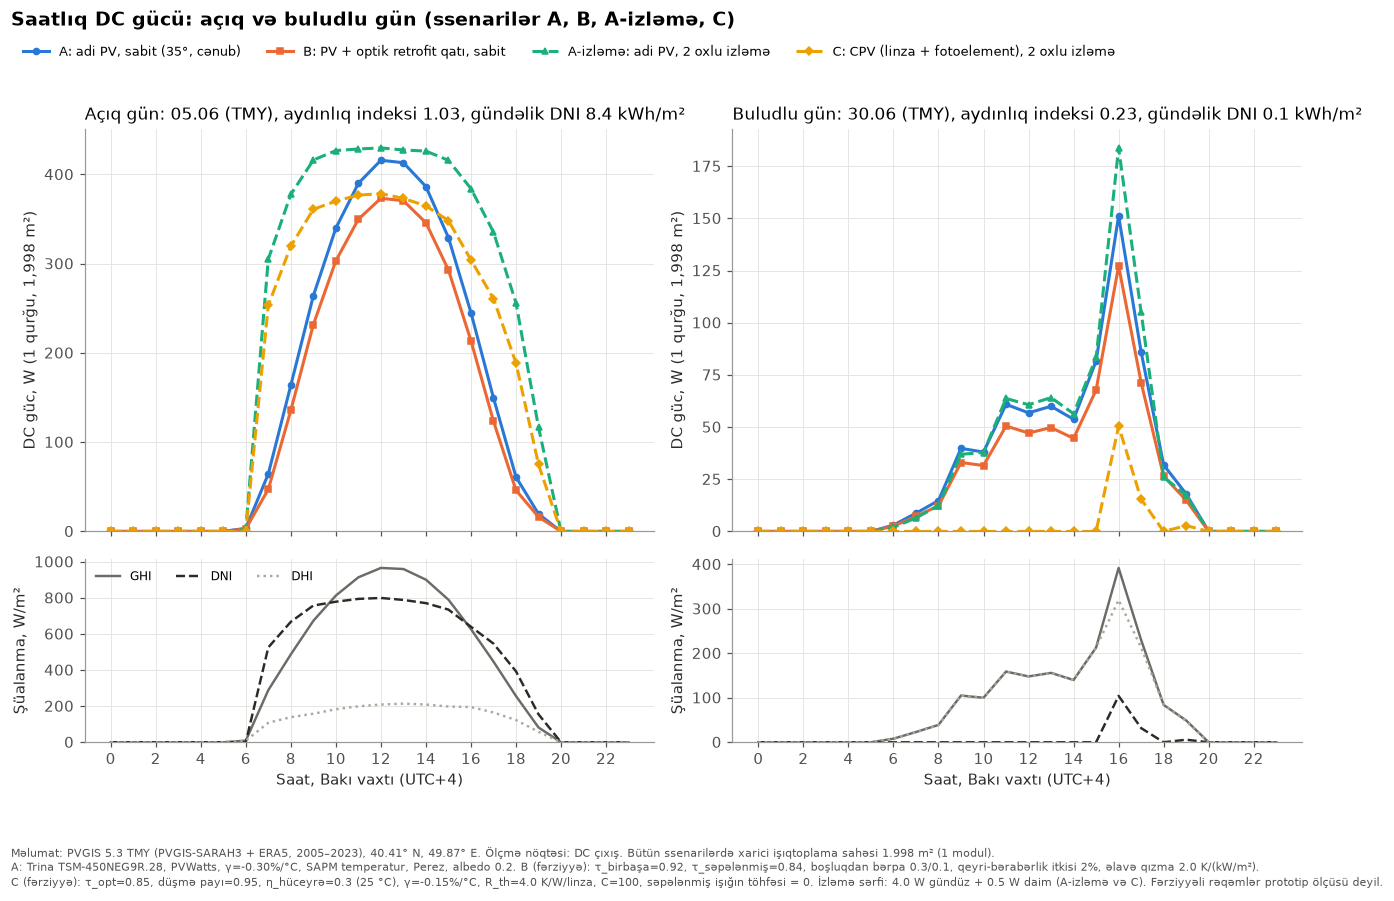

In [12]:
loc_idx = weather.index.tz_convert(LOCAL_TZ)
daily = pd.DataFrame({"ghi": weather["ghi"].values, "dni": weather["dni"].values,
                      "ghi_cs": geo["ghi_clearsky"].values}, index=loc_idx).resample("D").sum()
daily = daily[daily.index.year == TMY_YEAR]
daily["kt"] = daily["ghi"] / daily["ghi_cs"]
clear_day = daily["dni"].idxmax()
window = daily[(daily.index >= clear_day - pd.Timedelta(days=45)) & (daily.index <= clear_day + pd.Timedelta(days=45))]
cloudy_day = window["kt"].idxmin()

fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), sharex="col", gridspec_kw={"height_ratios": [2.2, 1]})
for col, (day, kind) in enumerate([(clear_day, "Açıq gün"), (cloudy_day, "Buludlu gün")]):
    sel = (loc_idx >= day) & (loc_idx < day + pd.Timedelta(days=1))
    hrs = loc_idx[sel].hour
    ax = axes[0, col]
    for s in SCENARIOS:
        ax.plot(hrs, res[s]["dc_W"].values[sel], LINESTYLES[s], color=COLORS[s], lw=2, marker=MARKERS[s], ms=4, label=LABELS[s])
    ax.set_title(f"{kind}: {day:%d.%m} (TMY), aydınlıq indeksi {daily.loc[day, 'kt']:.2f}, "
                 f"gündəlik DNI {daily.loc[day, 'dni'] / 1000:.1f} kWh/m²", loc="left")
    ax.set_ylabel("DC güc, W (1 qurğu, 1,998 m²)")
    ax.set_ylim(bottom=0)
    axb = axes[1, col]
    for comp, colr, lab in [("ghi", "#6c6b66", "GHI"), ("dni", "#2b2a27", "DNI"), ("dhi", "#a9a8a2", "DHI")]:
        axb.plot(hrs, weather[comp].values[sel], color=colr, lw=1.6, label=lab,
                 ls={"ghi": "-", "dni": "--", "dhi": ":"}[comp])
    axb.set_ylabel("Şüalanma, W/m²")
    axb.set_xlabel(f"Saat, {LOCAL_TZ_LABEL}")
    axb.set_xticks(range(0, 24, 2))
    axb.set_ylim(bottom=0)
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=4, fontsize=8.5)
axes[1, 0].legend(loc="upper left", fontsize=8, ncol=3)
fig.suptitle("Saatlıq DC gücü: açıq və buludlu gün (ssenarilər A, B, A-izləmə, C)", x=0.01, ha="left", fontsize=12.5,
             fontweight="bold")
fig.tight_layout(rect=(0, 0.11, 1, 0.93))
finish(fig, "fig1_hourly_dc_clear_vs_cloudy.png")

### Qrafik 2 — aylıq xalis enerji

Saxlanıldı: results\figures\fig2_monthly_net_energy.png


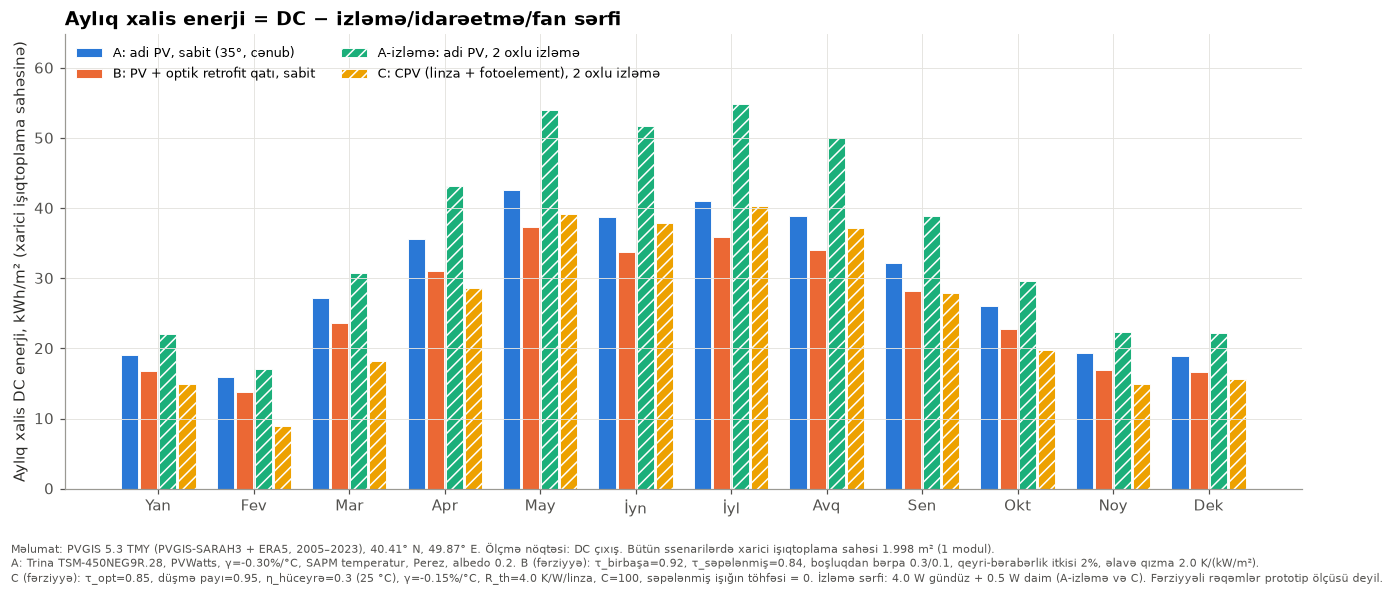

ay (Bakı vaxtı),1,2,3,4,5,6,7,8,9,10,11,12
A_fixed,19.10,15.88,27.22,35.54,42.63,38.72,41.04,38.94,32.16,26.00,19.30,18.87
B_fixed,16.74,13.74,23.68,30.99,37.33,33.81,35.87,34.11,28.18,22.78,16.90,16.59
A_2axis,22.13,17.09,30.78,43.22,54.02,51.72,54.91,49.95,38.92,29.66,22.37,22.16
C_2axis,14.92,9.00,18.22,28.59,39.14,37.90,40.35,37.11,27.93,19.84,14.94,15.70


In [13]:
month_idx = loc_idx.month
monthly = pd.DataFrame({s: (res[s]["net_W"].groupby(month_idx).sum().values * DT_H / 1000 / A_COLLECT_M2)
                        for s in SCENARIOS}, index=range(1, 13))
monthly.index.name = "ay (Bakı vaxtı)"
monthly.to_csv(RESULTS_DIR / "monthly_net_kWh_m2.csv", encoding="utf-8-sig")
MONTHS_AZ = ["Yan", "Fev", "Mar", "Apr", "May", "İyn", "İyl", "Avq", "Sen", "Okt", "Noy", "Dek"]

fig, ax = plt.subplots(figsize=(12, 5.4))
w_bar = 0.2
x = np.arange(12)
for i, s in enumerate(SCENARIOS):
    ax.bar(x + (i - 1.5) * w_bar, monthly[s].values, width=w_bar * 0.9, color=COLORS[s], label=LABELS[s],
           edgecolor="white", linewidth=0.6, hatch=("" if "fixed" in s else "///"))
ax.set_xticks(x, MONTHS_AZ)
ax.set_ylabel("Aylıq xalis DC enerji, kWh/m² (xarici işıqtoplama sahəsinə)")
ax.set_title("Aylıq xalis enerji = DC − izləmə/idarəetmə/fan sərfi", loc="left", fontsize=12.5, fontweight="bold")
ax.legend(ncol=2, loc="upper left", fontsize=8.5)
ax.set_ylim(0, monthly.values.max() * 1.18)
fig.tight_layout(rect=(0, 0.12, 1, 1))
finish(fig, "fig2_monthly_net_energy.png")
display(monthly.round(2).T)

### Qrafik 3 — illik xalis enerji, kWh/m²
Sütun — baza fərziyyələr; xətt — bütün fərziyyələrin birlikdə pessimist və optimist olduğu hallar arasında diapazon.

Saxlanıldı: results\figures\fig3_annual_net_kWh_per_m2.png


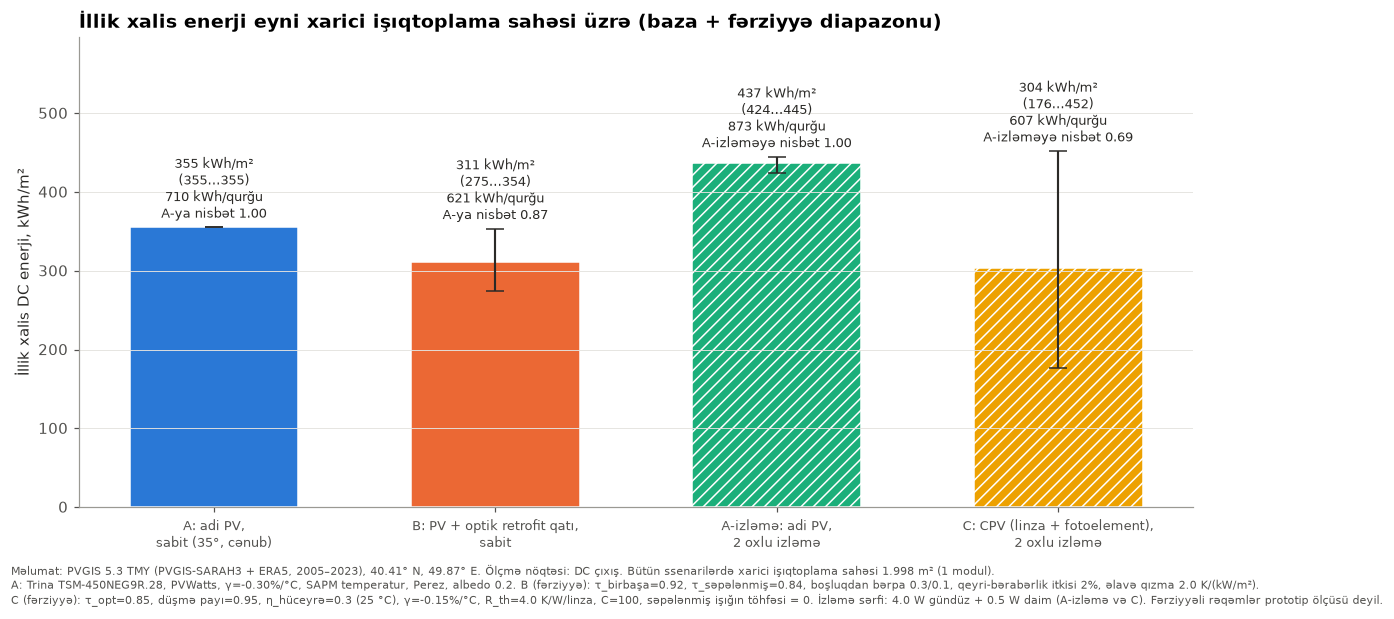

In [14]:
fig, ax = plt.subplots(figsize=(11, 5.6))
vals = [base_net[s] for s in SCENARIOS]
lo = [range_net.loc[s, "pessimist"] for s in SCENARIOS]
hi = [range_net.loc[s, "optimist"] for s in SCENARIOS]
yerr = np.array([[v - l for v, l in zip(vals, lo)], [h - v for v, h in zip(vals, hi)]])
bars = ax.bar(range(4), vals, color=[COLORS[s] for s in SCENARIOS], width=0.6, edgecolor="white",
              hatch=["" if "fixed" in s else "///" for s in SCENARIOS])
ax.errorbar(range(4), vals, yerr=np.abs(yerr), fmt="none", ecolor="#2b2a27", elinewidth=1.4, capsize=6)
for i, s in enumerate(SCENARIOS):
    ax.text(i, hi[i] + max(vals) * 0.015,
            f"{vals[i]:.0f} kWh/m²\n({lo[i]:.0f}…{hi[i]:.0f})\n"
            f"{annual.loc[s, 'xalis, kWh']:.0f} kWh/qurğu\n"
            + (f"A-ya nisbət {annual.loc[s, 'xalis / A_fixed']:.2f}" if "fixed" in s
               else f"A-izləməyə nisbət {annual.loc[s, 'xalis / A_2axis']:.2f}"),
            ha="center", va="bottom", fontsize=8.3, color="#2b2a27")
ax.set_xticks(range(4), [LABELS[s].replace(", ", ",\n", 1) for s in SCENARIOS], fontsize=8.6)
ax.set_ylabel("İllik xalis DC enerji, kWh/m²")
ax.set_ylim(0, max(hi) * 1.32)
ax.set_title("İllik xalis enerji eyni xarici işıqtoplama sahəsi üzrə (baza + fərziyyə diapazonu)", loc="left",
             fontsize=12.5, fontweight="bold")
ax.grid(axis="x", visible=False)
fig.tight_layout(rect=(0, 0.12, 1, 1))
finish(fig, "fig3_annual_net_kWh_per_m2.png")

### Qrafik 4 — CPV-nin adi panelə çatdığı hədd: optik ötürmə × fotoelement səmərəliliyi
Rəng: CPV illik xalis enerjisinin **A-izləmə**yə nisbəti (eyni izləmə strategiyası). Bütöv qara xətt — A-izləmə ilə bərabərlik,
qırıq xətt — sabit A ilə bərabərlik. Digər CPV parametrləri baza dəyərdədir
(düşmə payı, γ, R_th, izləmə sərfi). X oxu linzanın optik ötürməsidir (`τ_opt`), düşmə payı ayrıca vurulur.

Saxlanıldı: results\figures\fig4_cpv_breakeven_map.png


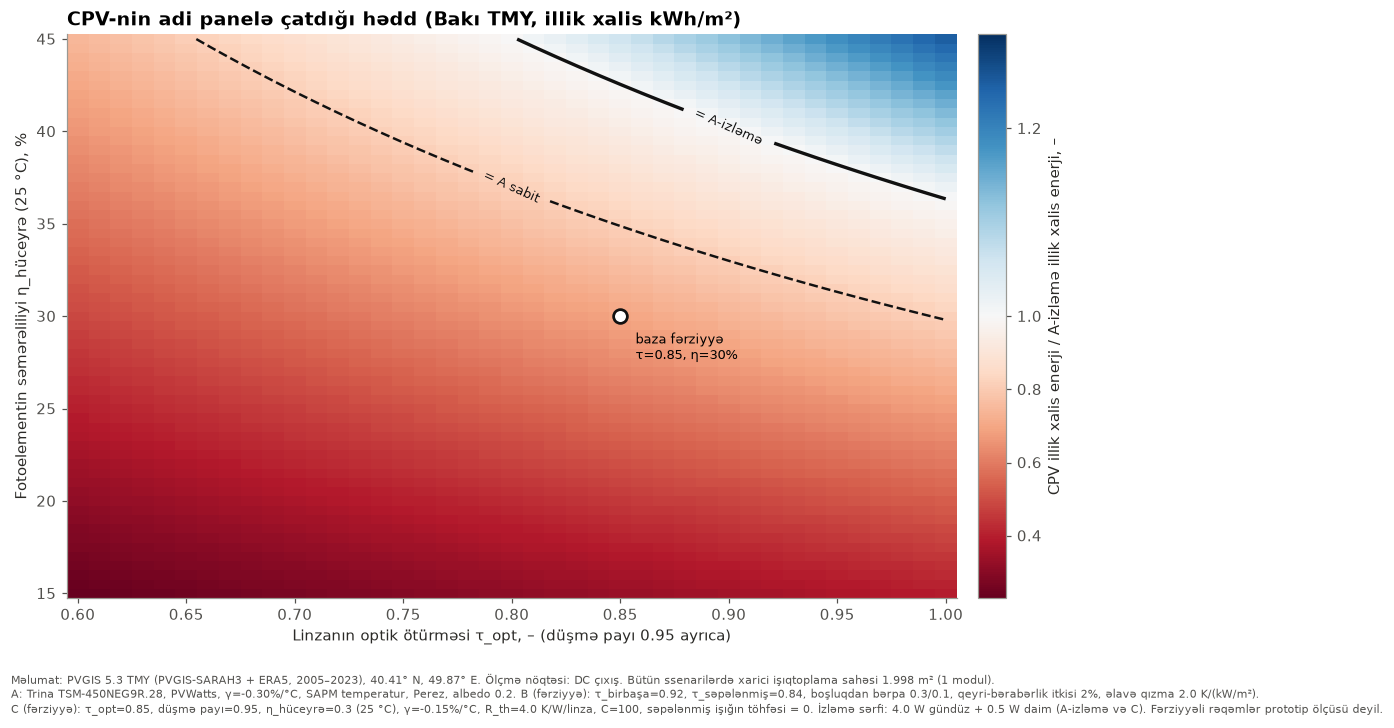

τ_opt=0.85 və düşmə payı 0.95 üçün CPV-nin bərabərləşdiyi minimal η_hüceyrə: A-izləmə ilə ≈ 0.430, sabit A ilə ≈ 0.350 (0,005 addımla)


In [15]:
taus = np.round(np.arange(0.60, 1.0001, 0.01), 4)
etas = np.round(np.arange(0.15, 0.4501, 0.005), 4)
aux_c_Wh = res["C_2axis"]["aux_W"].sum() * DT_H
dni_v, aoi_v, ta_v = weather["dni"], irr_trk["aoi"], weather["temp_air"]
Z = np.empty((len(etas), len(taus)))
for i, e in enumerate(etas):
    for j, t in enumerate(taus):
        p = cpv_dc(dni_v, aoi_v, ta_v, dict(CPV, tau_optical=t, eta_cell_ref=e), SYSTEM)["dc_W"].sum() * DT_H
        Z[i, j] = (p - aux_c_Wh) / 1000 / A_COLLECT_M2
ratio_trk = Z / base_net["A_2axis"]
ratio_fix = Z / base_net["A_fixed"]

fig, ax = plt.subplots(figsize=(10.5, 6.6))
norm = TwoSlopeNorm(vmin=min(ratio_trk.min(), 0.5), vcenter=1.0, vmax=max(ratio_trk.max(), 1.3))
pm = ax.pcolormesh(taus, etas * 100, ratio_trk, cmap="RdBu", norm=norm, shading="nearest")
cb = fig.colorbar(pm, ax=ax, pad=0.02)
cb.set_label("CPV illik xalis enerji / A-izləmə illik xalis enerji, –")
cs1 = ax.contour(taus, etas * 100, ratio_trk, levels=[1.0], colors="#111111", linewidths=2.2)
cs2 = ax.contour(taus, etas * 100, ratio_fix, levels=[1.0], colors="#111111", linewidths=1.6, linestyles="--")
ax.clabel(cs1, fmt={1.0: "= A-izləmə"}, fontsize=8.5)
ax.clabel(cs2, fmt={1.0: "= A sabit"}, fontsize=8.5)
ax.plot(CPV["tau_optical"], CPV["eta_cell_ref"] * 100, marker="o", ms=9, mfc="white", mec="#111111", mew=1.8)
ax.annotate(f"baza fərziyyə\nτ={CPV['tau_optical']}, η={CPV['eta_cell_ref']:.0%}", (CPV["tau_optical"], CPV["eta_cell_ref"] * 100),
            xytext=(10, -28), textcoords="offset points", fontsize=8.5)
ax.set_xlabel(f"Linzanın optik ötürməsi τ_opt, – (düşmə payı {CPV['intercept_factor']} ayrıca)")
ax.set_ylabel("Fotoelementin səmərəliliyi η_hüceyrə (25 °C), %")
ax.set_title("CPV-nin adi panelə çatdığı hədd (Bakı TMY, illik xalis kWh/m²)", loc="left", fontsize=12.5, fontweight="bold")
ax.grid(False)
fig.tight_layout(rect=(0, 0.12, 1, 1))
finish(fig, "fig4_cpv_breakeven_map.png")


def breakeven_eta(ratio, tau):
    j = int(np.argmin(np.abs(taus - tau)))
    col = ratio[:, j]
    above = np.where(col >= 1.0)[0]
    return float(etas[above[0]]) if len(above) else float("nan")

be = {"A_2axis": breakeven_eta(ratio_trk, CPV["tau_optical"]), "A_fixed": breakeven_eta(ratio_fix, CPV["tau_optical"])}
print(f"τ_opt={CPV['tau_optical']} və düşmə payı {CPV['intercept_factor']} üçün CPV-nin bərabərləşdiyi minimal η_hüceyrə: "
      f"A-izləmə ilə ≈ {be['A_2axis']:.3f}, sabit A ilə ≈ {be['A_fixed']:.3f} (0,005 addımla)")

## 9. Nəticələr
### 9.1 Avtomatik xülasə (cari parametrlərlə hesablanıb)

In [16]:
# where does each option win? -> by sky condition (diffuse fraction) and by month
day = weather["ghi"] > 10
kd = (weather["dhi"] / weather["ghi"]).where(day)
bins = pd.cut(kd, [0, 0.3, 0.5, 0.7, 0.9, 1.0001], right=False,
              labels=["0–0,3 (ən aydın)", "0,3–0,5", "0,5–0,7", "0,7–0,9", "0,9–1 (tam buludlu)"])
by_sky = pd.DataFrame({s: res[s]["dc_W"].groupby(bins, observed=False).sum() / 1000 / A_COLLECT_M2 for s in SCENARIOS})
by_sky["saat sayı"] = bins.value_counts().reindex(by_sky.index)
by_sky["B / A"] = by_sky["B_fixed"] / by_sky["A_fixed"]
by_sky["C / A-izləmə"] = by_sky["C_2axis"] / by_sky["A_2axis"]
by_sky.index.name = "səpələnmiş pay DHI/GHI"
by_sky.to_csv(RESULTS_DIR / "dc_by_diffuse_fraction_kWh_m2.csv", encoding="utf-8-sig")
display(by_sky.style.format(precision=2))

m_ratio = pd.DataFrame({"B / A": monthly["B_fixed"] / monthly["A_fixed"],
                        "C / A-izləmə": monthly["C_2axis"] / monthly["A_2axis"],
                        "C / A": monthly["C_2axis"] / monthly["A_fixed"]}, index=monthly.index)
m_ratio.index = MONTHS_AZ
display(m_ratio.T.style.format("{:.2f}"))

# break-even of the retrofit: required beam gap recovery for B = A (other B assumptions at base)
grid_r = np.round(np.arange(0.0, 1.0001, 0.02), 3)
b_vals = []
for rr in grid_r:
    rb = pv_flat_dc(irr_fixed, iam_fixed, weather, MODULE, SYSTEM, retrofit=dict(RETROFIT, gap_recovery_beam=rr, gap_recovery_diffuse=rr))
    b_vals.append(rb["net_W"].sum() / 1000 / A_COLLECT_M2)
b_vals = np.array(b_vals)
idx_be = np.where(b_vals >= base_net["A_fixed"])[0]
r_be_txt = (f"boşluqdan bərpa payı r ≈ **{grid_r[idx_be[0]]:.2f}** olmalıdır" if len(idx_be) else
            f"r-in heç bir dəyəri (0…1) kifayət etmir: r = 1 olduqda belə **B/A = {b_vals[-1] / base_net['A_fixed']:.3f}**")
b_perfect = pv_flat_dc(irr_fixed, iam_fixed, weather, MODULE, SYSTEM, retrofit=dict(
    RETROFIT, tau_beam_normal=1.0, tau_diffuse=1.0, gap_recovery_beam=1.0, gap_recovery_diffuse=1.0,
    nonuniformity_loss=0.0, extra_heating_K_per_kWm2=0.0))["net_W"].sum() / 1000 / A_COLLECT_M2

# required add-on transmittance (same for beam and diffuse) for B = A, with no mismatch loss and no extra heating
tau_grid = np.round(np.arange(0.85, 1.0001, 0.005), 3)
tau_req = {}
for rr in (0.5, 1.0):
    ok = [t for t in tau_grid if pv_flat_dc(irr_fixed, iam_fixed, weather, MODULE, SYSTEM, retrofit=dict(
        RETROFIT, tau_beam_normal=t, tau_diffuse=t, gap_recovery_beam=rr, gap_recovery_diffuse=rr,
        nonuniformity_loss=0.0, extra_heating_K_per_kWm2=0.0))["net_W"].sum() / 1000 / A_COLLECT_M2 >= base_net["A_fixed"]]
    tau_req[rr] = ok[0] if ok else float("nan")

top_meas = (sens.assign(s=sens["ssenari"]).sort_values("swing, kWh/m²", ascending=False)
            .groupby("ssenari").head(3)[["ssenari", "parametr", "swing, kWh/m²", "swing, % baza"]])

lines = []
if IS_SAMPLE:
    lines.append("**⚠️ NÜMUNƏ MƏLUMAT — bu rəqəmlər Bakı üçün nəticə deyil.**\n")
lines.append(f"Məlumat: {DATA_LABEL}. Sahə: {A_COLLECT_M2:.3f} m² (bütün ssenarilər). Ölçmə nöqtəsi: DC.\n")
lines.append("| ssenari | illik xalis, kWh/m² | diapazon (pess.…opt.) | nisbət |")
lines.append("|---|---|---|---|")
for s in SCENARIOS:
    rel = (f"{annual.loc[s, 'xalis / A_fixed']:.3f} × A" if "fixed" in s else f"{annual.loc[s, 'xalis / A_2axis']:.3f} × A-izləmə; "
           f"{annual.loc[s, 'xalis / A_fixed']:.3f} × A")
    lines.append(f"| {LABELS[s]} | {base_net[s]:.1f} | {range_net.loc[s, 'pessimist']:.1f}…{range_net.loc[s, 'optimist']:.1f} | {rel} |")
lines.append("")
lines.append(f"* B-nin A-ya bərabərləşməsi üçün (digər B fərziyyələri baza, r birbaşa və səpələnmiş üçün eyni) {r_be_txt}. "
             f"İdeal halda (τ=1, r=1, itki və qızma yoxdur) B = {b_perfect:.1f} kWh/m², yəni A-dan "
             f"{100 * (b_perfect / base_net['A_fixed'] - 1):+.1f}% — bu, aktiv sahə payı f_akt={MODULE['active_area_fraction']} üçün yuxarı həddir.")
lines.append(f"* Qeyri-bərabərlik itkisi və əlavə qızma sıfır olsa belə, B = A üçün əlavə qatın ötürməsi (birbaşa = səpələnmiş) "
             f"r = 1 olduqda ≥ **{tau_req[1.0]:.3f}**, r = 0,5 olduqda ≥ **{tau_req[0.5]:.3f}** olmalıdır "
             f"(normal düşmədə; bucaq itkisi əlavədir).")
lines.append(f"* CPV (τ_opt={CPV['tau_optical']}, düşmə payı {CPV['intercept_factor']}) A-izləməyə η_hüceyrə ≈ **{be['A_2axis']:.3f}**, "
             f"sabit A-ya isə η_hüceyrə ≈ **{be['A_fixed']:.3f}** olduqda çatır (fərziyyəli fotoelement; kommersiya məhsulu haqqında nəticə deyil).")
lines.append(f"* Səpələnmiş pay DHI/GHI < 0,3 olan {int(by_sky['saat sayı'].iloc[0])} saatda C / A-izləmə = "
             f"{by_sky['C / A-izləmə'].iloc[0]:.2f}, B / A = {by_sky['B / A'].iloc[0]:.2f}; DHI/GHI ≥ 0,9 olan "
             f"{int(by_sky['saat sayı'].iloc[-1])} saatda C / A-izləmə = {by_sky['C / A-izləmə'].iloc[-1]:.2f}, "
             f"B / A = {by_sky['B / A'].iloc[-1]:.2f}.")
lines.append(f"* Aylar üzrə C / A-izləmə: min {m_ratio['C / A-izləmə'].min():.2f} ({m_ratio['C / A-izləmə'].idxmin()}), "
             f"maks {m_ratio['C / A-izləmə'].max():.2f} ({m_ratio['C / A-izləmə'].idxmax()}).")
lines.append("\n**İllik nəticəyə ən çox təsir edən fərziyyələr (ölçmə prioriteti):**\n")
try:
    lines.append(top_meas.to_markdown(index=False, floatfmt=".2f"))
except ImportError:  # tabulate not installed
    lines.append("```\n" + top_meas.to_string(index=False) + "\n```")
try:
    display(Markdown("\n".join(lines)))
except Exception:  # noqa: BLE001
    print("\n".join(lines))

,A_fixed,B_fixed,A_2axis,C_2axis,saat sayı,B / A,C / A-izləmə
səpələnmiş pay DHI/GHI,,,,,,,
"0–0,3 (ən aydın)",149.28,133.40,169.01,144.22,827,0.89,0.85
"0,3–0,5",104.81,91.47,150.58,115.49,895,0.87,0.77
"0,5–0,7",42.36,36.33,62.64,37.77,539,0.86,0.60
"0,7–0,9",30.98,26.26,39.76,15.79,532,0.85,0.40
"0,9–1 (tam buludlu)",27.70,23.06,25.86,1.46,1169,0.83,0.06


,Yan,Fev,Mar,Apr,May,İyn,İyl,Avq,Sen,Okt,Noy,Dek
B / A,0.88,0.87,0.87,0.87,0.88,0.87,0.87,0.88,0.88,0.88,0.88,0.88
C / A-izləmə,0.67,0.53,0.59,0.66,0.72,0.73,0.73,0.74,0.72,0.67,0.67,0.71
C / A,0.78,0.57,0.67,0.80,0.92,0.98,0.98,0.95,0.87,0.76,0.77,0.83


Məlumat: PVGIS 5.3 TMY (PVGIS-SARAH3 + ERA5, 2005–2023), 40.41° N, 49.87° E. Sahə: 1.998 m² (bütün ssenarilər). Ölçmə nöqtəsi: DC.

| ssenari | illik xalis, kWh/m² | diapazon (pess.…opt.) | nisbət |
|---|---|---|---|
| A: adi PV, sabit (35°, cənub) | 355.4 | 355.4…355.4 | 1.000 × A |
| B: PV + optik retrofit qatı, sabit | 310.7 | 274.7…353.7 | 0.874 × A |
| A-izləmə: adi PV, 2 oxlu izləmə | 436.9 | 423.6…444.9 | 1.000 × A-izləmə; 1.229 × A |
| C: CPV (linza + fotoelement), 2 oxlu izləmə | 303.6 | 176.1…452.2 | 0.695 × A-izləmə; 0.854 × A |

* B-nin A-ya bərabərləşməsi üçün (digər B fərziyyələri baza, r birbaşa və səpələnmiş üçün eyni) r-in heç bir dəyəri (0…1) kifayət etmir: r = 1 olduqda belə **B/A = 0.933**. İdeal halda (τ=1, r=1, itki və qızma yoxdur) B = 383.3 kWh/m², yəni A-dan +7.8% — bu, aktiv sahə payı f_akt=0.92 üçün yuxarı həddir.
* Qeyri-bərabərlik itkisi və əlavə qızma sıfır olsa belə, B = A üçün əlavə qatın ötürməsi (birbaşa = səpələnmiş) r = 1 olduqda ≥ **0.930**, r = 0,5 olduqda ≥ **0.970** olmalıdır (normal düşmədə; bucaq itkisi əlavədir).
* CPV (τ_opt=0.85, düşmə payı 0.95) A-izləməyə η_hüceyrə ≈ **0.430**, sabit A-ya isə η_hüceyrə ≈ **0.350** olduqda çatır (fərziyyəli fotoelement; kommersiya məhsulu haqqında nəticə deyil).
* Səpələnmiş pay DHI/GHI < 0,3 olan 827 saatda C / A-izləmə = 0.85, B / A = 0.89; DHI/GHI ≥ 0,9 olan 1169 saatda C / A-izləmə = 0.06, B / A = 0.83.
* Aylar üzrə C / A-izləmə: min 0.53 (Fev), maks 0.74 (Avq).

**İllik nəticəyə ən çox təsir edən fərziyyələr (ölçmə prioriteti):**

| ssenari   | parametr                    |   swing, kWh/m² |   swing, % baza |
|:----------|:----------------------------|----------------:|----------------:|
| C_2axis   | CPV.eta_cell_ref            |          137.67 |           45.34 |
| C_2axis   | CPV.tau_optical             |           61.71 |           20.32 |
| C_2axis   | CPV.intercept_factor        |           35.72 |           11.76 |
| B_fixed   | RETROFIT.nonuniformity_loss |           19.02 |            6.12 |
| B_fixed   | RETROFIT.tau_diffuse        |           17.67 |            5.69 |
| B_fixed   | RETROFIT.tau_beam_normal    |           16.27 |            5.24 |
| A_2axis   | TRACKER.tracker_aux_W       |           15.58 |            3.56 |
| A_2axis   | TRACKER.controller_aux_W    |            5.70 |            1.30 |

### 9.2 Xarici çarpaz yoxlama: PVGIS PVcalc (məlumat üçün)
Model A-nı PVGIS-in öz PV kalkulyatoru ilə müqayisə edirik (eyni nöqtə, 0,45 kWp, 35°, cənub, sistem itkisi 0%).
PVGIS çoxillik ortalama, öz temperatur və aşağı işıq modeli işlədir, ona görə bir neçə faizlik fərq gözlənilir. Bu, kalibrləmə deyil.

In [17]:
try:
    _r = requests.get(PVGIS_API + "PVcalc", timeout=60, params=dict(
        lat=SITE["latitude"], lon=SITE["longitude"], peakpower=MODULE["pdc0_W"] / 1000, loss=0,
        angle=SYSTEM["tilt_deg"], aspect=SYSTEM["azimuth_deg"] - 180, pvtechchoice="crystSi",
        mountingplace="free", outputformat="json"))
    _r.raise_for_status()
    _pv = _r.json()
    e_y = _pv["outputs"]["totals"]["fixed"]["E_y"]
    h_y = _pv["outputs"]["totals"]["fixed"]["H(i)_y"]
    print(f"PVGIS PVcalc ({_pv['inputs']['meteo_data']['radiation_db']}): E_y = {e_y:.1f} kWh/il (sistem itkisi 0%, temperatur və aşağı işıq itkisi daxil), "
          f"POA = {h_y:.0f} kWh/m²")
    print(f"Bu notebook, A_fixed: DC = {annual.loc['A_fixed', 'DC, kWh']:.1f} kWh/il, POA = {irr_fixed['poa_global'].sum() / 1000:.0f} kWh/m²"
          f" → nisbət {annual.loc['A_fixed', 'DC, kWh'] / e_y:.3f}")
except Exception as exc:  # noqa: BLE001
    print("PVGIS PVcalc çarpaz yoxlaması icra olunmadı:", repr(exc))

PVGIS PVcalc (PVGIS-SARAH3): E_y = 694.9 kWh/il (sistem itkisi 0%, temperatur və aşağı işıq itkisi daxil), POA = 1675 kWh/m²
Bu notebook, A_fixed: DC = 710.1 kWh/il, POA = 1679 kWh/m² → nisbət 1.022


### 9.3 Şərh

*Bu şərh 2026-11-08 tarixində baza parametrlərlə və PVGIS 5.3 TMY (SARAH3 + ERA5) məlumatı ilə aparılmış icraya aiddir.
Parametrləri dəyişsəniz, 9.1-dəki avtomatik xülasə yenilənir, bu mətn isə dəyişmir. B və C üzrə bütün rəqəmlər **fərziyyəli optika və fotoelementə** əsaslanır.
Onlar prototip ölçüsü və ya kommersiya məhsulu haqqında nəticə deyil.*

**Modelin özünün yoxlanması.** Adi panel modeli STC-də 450 W verir. NOCT-da SAPM hüceyrə temperaturunu 45,9 °C hesablayır (pasport 43 ± 2 °C), güc isə 337,5 W alınır (pasport 343 W, −1,6%).
İllik nəticə PVGIS-in öz PV kalkulyatoru ilə 2,2% daxilində üst-üstə düşür. Bütün məcburi yoxlamalar keçdi.

**Hansı şəraitdə hansı variant üstündür (baza fərziyyələr):**

1. **Sabit qurğular, B ↔ A.** Optik retrofit illik xalis enerjidə adi paneldən təxminən 13% geri qalır (311 və 355 kWh/m²).
   Bütün B fərziyyələri birlikdə optimist götürüləndə belə B yalnız A-ya çatır (354 kWh/m²), onu keçmir.
   Səbəbi sadədir. Əlavə qat birbaşa işığın təxminən 8%-ni, səpələnmiş işığın təxminən 16%-ni itirir. Hüceyrələr arasındakı boşluqdan geri qaytarıla bilən işıq isə
   aktiv sahə payı 0,92 olduqda ən çoxu təxminən 8,7%-dir. İdeal, itkisiz optikada belə yuxarı hədd +7,8%-dir.
   B-nin nisbi itkisi səpələnmiş payı yüksək olan saatlarda daha böyükdür, yəni retrofit buludlu havada daha zəif işləyir.
   Uyğunsuzluq itkisi və əlavə qızma sıfır olsa belə, B-nin A-ya çatması üçün əlavə qatın ötürməsi boşluq işığının hamısı yönəldildikdə (r = 1) ≥ 0,93,
   yarısı yönəldildikdə (r = 0,5) isə ≥ 0,97 olmalıdır.
   **Nəticə:** retrofitin mənası yalnız bu üç şərt birlikdə ödənsə ola bilər: çox yüksək ötürmə, boşluğa düşən işığın böyük hissəsinin hüceyrələrə yönəlməsi və demək olar ki, sıfır uyğunsuzluq itkisi.
2. **Eyni izləmə strategiyası, C ↔ A-izləmə.** Baza CPV (τ_opt 0,85, düşmə payı 0,95, η 30%) A-izləmənin 0,69-u qədər enerji verir.
   Ən aydın saatlarda da CPV geri qalır. Buludlu saatlarda isə demək olar ki, heç nə vermir, çünki səpələnmiş işıqdan töhfə sıfır qəbul edilib.
   Bakının TMY-sində izləmə müstəvisinə düşən illik işığın yalnız ~62%-i birbaşa işıqdır (1315 / 2112 kWh/m²).
   Qış aylarında CPV-nin nisbi göstəricisi daha aşağıdır: ən zəif ay fevraldır (0,53), ən yaxşı ay avqustdur (0,74).
   Xəritəyə görə, τ_opt = 0,85 və düşmə payı 0,95 olduqda CPV A-izləməyə **η ≈ 43%**-də, sabit A-ya **η ≈ 35%**-də çatır (fotoelement 25 °C-də, optik gücə nisbətən).
   Bu hədd fərziyyəli optika üçündür. Real fotoelementin yüksək intensivlikdə və faktiki spektrdə səmərəliliyi ölçülmədən CPV-nin üstünlüyü barədə nəticə çıxarmaq olmaz.
3. **İzləmənin özü.** Eyni adi panel 2 oxlu izləmədə, sərf çıxıldıqdan sonra, sabit qurğudan ~23% çox xalis enerji verir (437 və 355 kWh/m²).
   Bu fərq izləmə sərfi fərziyyəsinə zəif həssasdır (423…445 kWh/m²). Ona görə CPV-ni sabit panellə müqayisə etmək izləmənin təsirini linzanın təsiri ilə qarışdırar.
   Ədalətli müqayisə C ↔ A-izləmədir.
4. **Ümumi mənzərə.** Bu ilkin qiymətləndirmədə eyni işıqtoplama sahəsində **adi panel (sabit və ya izləməli) hər iki linzalı variantdan üstündür**.
   Linzalı variantlar yalnız fərziyyə diapazonunun optimist kənarında rəqabətə girir.

**Prototipdə ilk növbədə ölçülməli parametrlər (həssaslıq sırası ilə):**

* **CPV:**
  1. fotoelementin səmərəliliyi işçi intensivlikdə (~70 kW/m², C = 100) və temperaturda: illik nəticə ±45% dəyişir;
  2. linzanın spektral optik ötürməsi (±20%);
  3. fokusun fotoelementə düşmə payı, izləmə xətası və aberrasiya ilə birlikdə (±12%);
  4. izləmə və idarəetmə sərfi;
  5. fotoelement–ətraf mühit istilik müqaviməti və faktiki hüceyrə temperaturu;
  6. linzanın çirklənməsi (ilk versiyada 0 qəbul edilib).
* **Retrofit:**
  1. qeyri-bərabər işıqlanmanın yaratdığı uyğunsuzluq itkisi: hüceyrə üzrə işıq xəritəsi və modulun I–V əyrisi ölçülməlidir;
  2. səpələnmiş işıq üçün hemisferik ötürmə;
  3. birbaşa işığın normal düşmədə ötürməsi və onun 0–70° bucaqlarda dəyişməsi;
  4. boşluqdan hüceyrəyə yönəlmə payı;
  5. modulun faktiki aktiv sahə payı;
  6. əlavə qızma (qatlı və qatsız modulun eyni şəraitdə hüceyrə temperaturu).
* **Hər iki variant üçün ümumi:** adi panelin Bakı şəraitində hüceyrə temperaturu (SAPM modeli NOCT-dan ~2,9 K yüksək verir) və DC çıxışda eyni ölçmə üsulu.

**İcra edilməyən hissələr və qalan addımlar:**

* **CEC/De Soto I–V modeli** əlavə edilməyib. pvlib-in CEC verilənlər bazasında (21 535 modul) TSM-450NEG9R.28 yoxdur, ilk versiyada da I–V əyrisi tələb olunmur.
  Növbəti addım: pasportdakı `Voc`, `Isc`, `Vmp`, `Imp` və temperatur əmsallarından `pvlib.ivtools.sdm.fit_cec_sam` (NREL-PySAM paketi lazımdır) ilə parametrləri çıxarmaq.
  Sonra retrofitdə hüceyrə işıq xəritəsi ilə ardıcıl hüceyrələrin (və bypass diodlarının) cərəyan uyğunsuzluğunu hesablamaq.
* **CPV fotoelementinin intensivlik və spektr asılılığı** ilk versiyada yoxdur. Konkret fotoelement seçildikdən sonra onun ölçülmüş η(I, T) xəritəsi daxil edilməlidir.
* **İstifadəçinin göstərdiyi 2024_C texniki pasportu** serverdə tapılmadı. Rəsmi 2023_B versiyasında temperatur əmsalı −0,30%/°C-dir.
  −0,29%/°C işlədilsə, illik nəticə cəmi +0,1…0,15% dəyişir və nəticələrə təsir etmir.